In [3]:
%cd ../src

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\dnn_env\Lib\site-packages\IPython\core\magics\osm.py:417: UserWarning: This is now an optional IPython functionality, setting dhist requires you to install the `pickleshare` library.
  self.shell.db['dhist'] = compress_dhist(dhist)[-100:]


In [4]:
%load_ext autoreload
%autoreload 2

In [ ]:
dnn.sqmmd_est2

In [23]:
# local modules
import dnn
import cross_validate_dnn as cv_dnn
import scaler_methods

# packages
import numpy as np
import pandas as pd
from itertools import chain
import itertools
from matplotlib.pyplot import matshow
import matplotlib.pyplot as plt
import matplotlib as mpl
import math
import random


## Plot settings

In [6]:
plt.rc('font', family='serif')
plt.rc('text', usetex=False)
plt.rc('axes', axisbelow=True)
label_size = 15
mpl.rcParams['xtick.labelsize'] = label_size 
mpl.rcParams['ytick.labelsize'] = label_size 
mpl.rcParams['axes.labelsize'] = label_size
mpl.rcParams['axes.titlesize'] = label_size
mpl.rcParams['figure.titlesize'] = label_size
mpl.rcParams['lines.markersize'] = label_size
mpl.rcParams['grid.linewidth'] = 2.5
mpl.rcParams['legend.fontsize'] = label_size


lss = ['--',  ':', '-.', '-', '--', '-.', ':', '-', '--', '-.', ':', '-']
mss = ['x', 'o', '>', 's', 'D', '>', 'D', '>', 's', 'o', 'D']


## Import data

In [7]:
# mmd_estimates_exp = np.load("../data_checkpoints/mmd_exp_estimates_v6.npy", allow_pickle = True)
# mmd_estimates_sq = np.load("../data_checkpoints/mmd_sq_estimates_v6.npy", allow_pickle = True)
# ws2_estimates = np.load("../data_checkpoints/ws2_estimates_v6.npy")

# nn_ws2 = np.load('../data_checkpoints/ws2_nncount_v6.npy')
# nn_mmd_exp = np.load('../data_checkpoints/mmd_exp_nncount_v6.npy')
# nn_mmd_sq = np.load('../data_checkpoints/mmd_sq_nncount_v6.npy')

M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape


## NN Density

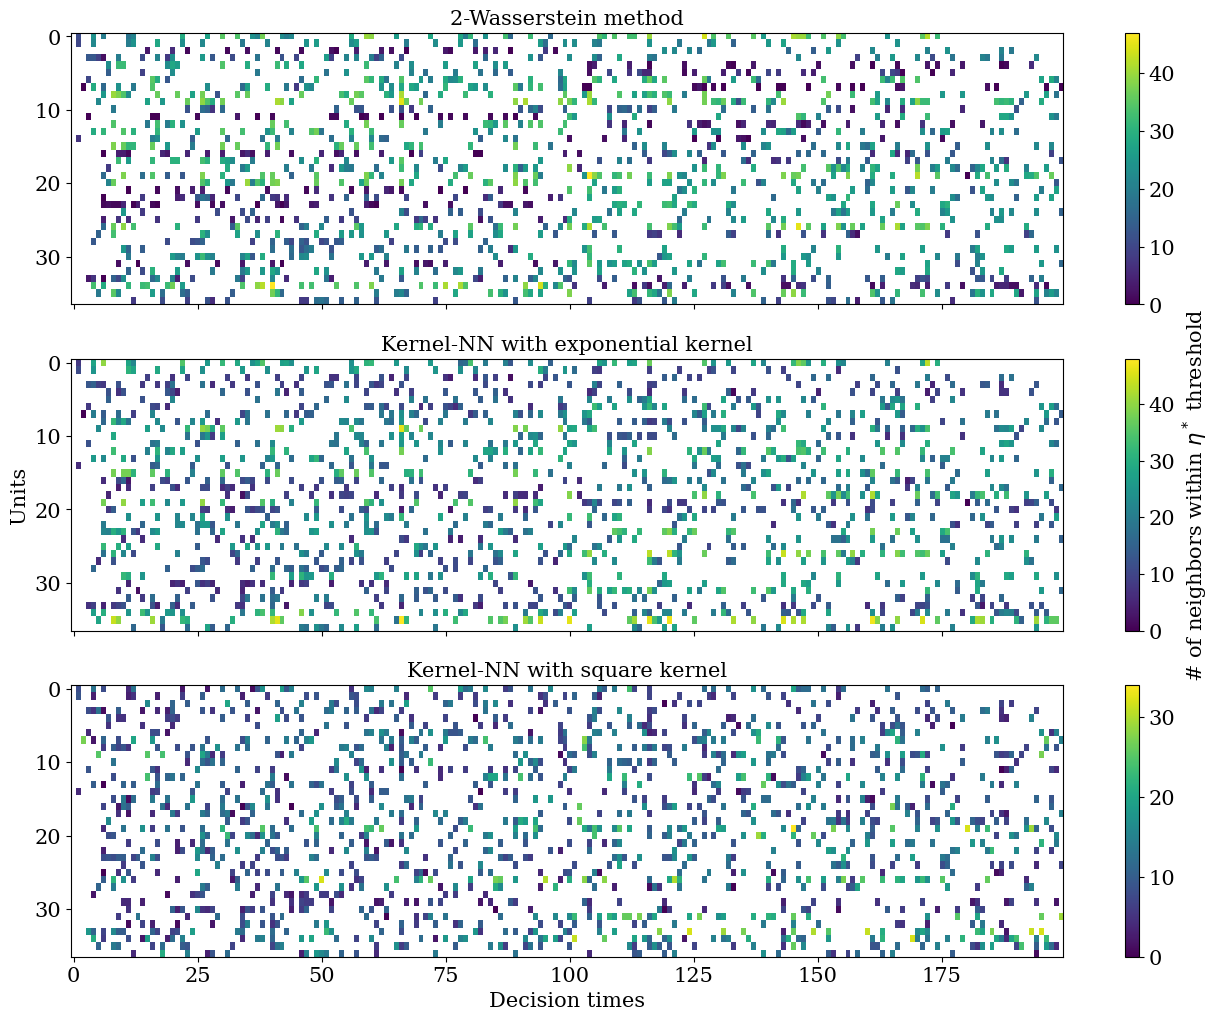

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(16, 12), nrows = 3)


pos1 = ax1.imshow(nn_ws2, aspect = 'auto')
pos2 = ax2.imshow(nn_mmd_exp, aspect = 'auto')
pos3 = ax3.imshow(nn_mmd_sq, aspect = 'auto')

fig.colorbar(pos1, ax = ax1)
fig.colorbar(pos2, ax = ax2, label = "# of neighbors within $\eta^*$ threshold")
fig.colorbar(pos3, ax = ax3)

ax3.set_xlabel("Decision times")
ax2.set_ylabel("Units")

ax1.get_xaxis().set_ticklabels([])
ax2.get_xaxis().set_ticklabels([])

ax1.set_title("2-Wasserstein method")
ax2.set_title("Kernel-NN with exponential kernel")
ax3.set_title("Kernel-NN with square kernel")

#fig.suptitle("2-sample Kolmogorov-Smirnov test statistic by DNN method")
plt.savefig("nn_density.pdf", bbox_inches = "tight")

In [ ]:
pd.DataFrame(eta_stars)

,0,1,2,3,4,5
0,27315.647494,14273.827171,0.131236,0.118890,1.486350e+06,1.780220e+06
1,25233.380591,32121.161560,0.069433,0.680192,2.763500e+06,2.981171e+03
2,14034.618539,277.667666,0.069096,0.017171,2.231530e+05,2.643864e+06
3,6722.518848,4845.472739,0.043877,0.022818,1.278810e+06,8.703357e+04
4,224.335496,49537.294494,0.010180,0.022065,2.620052e+05,1.305722e+05
5,1071.874236,30882.142852,0.182946,0.153007,2.024771e+06,1.105770e+06
6,40202.723768,19869.296946,0.198140,0.013633,7.378112e+05,5.104529e+05
7,36.520898,12799.392623,0.098216,0.057871,2.983701e+06,2.409755e+06
8,25942.271339,42313.062922,0.038144,0.074009,2.205073e+06,5.175422e+05
9,23383.902193,49972.994693,0.094910,0.456008,2.358859e+05,2.314807e+06


### Reproduce CDFs using NN density rather than TS-test

(array([220., 126., 140., 137., 231., 247., 163., 163.,  52.,   6.]),
 array([ 0. ,  4.7,  9.4, 14.1, 18.8, 23.5, 28.2, 32.9, 37.6, 42.3, 47. ]),
 <BarContainer object of 10 artists>)

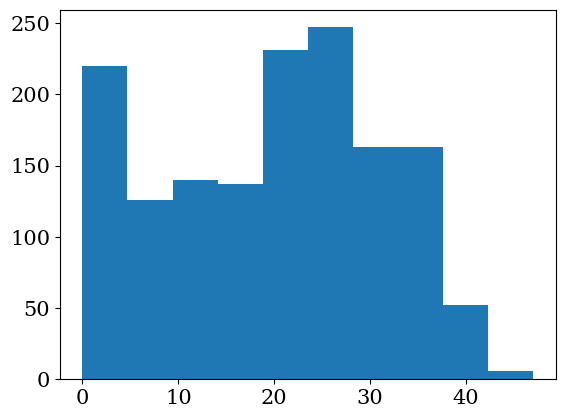

In [16]:
plt.hist(nn_ws2.flatten())

In [43]:
random.seed(a=30)
high_nn_ws2= np.nonzero(nn_ws2[0] >= 30)
rand_num = random.randrange(len(high_nn_ws2[0]))
ws2_i = 0 #high_nn_ws2[0][rand_num]
ws2_j = high_nn_ws2[0][rand_num]

nn_ws2[ws2_i, ws2_j]


np.float64(35.0)

In [18]:
ws2_j

np.int64(145)

In [89]:
random.seed(a=200)
mid_nn_ws2 = np.nonzero((nn_ws2[0] < 30) & (nn_ws2[0] > 20))
print(len(mid_nn_ws2[0]))
rand_num = random.randrange(len(mid_nn_ws2[0]))
ws2_i_mid = 0#mid_nn_ws2[0][rand_num]
ws2_j_mid = mid_nn_ws2[0][rand_num]

nn_ws2[ws2_i_mid, ws2_j_mid]

15


np.float64(24.0)

In [20]:
rand_num

1

In [39]:
random.seed(a=40)
poor_nn_ws2 = np.nonzero((nn_ws2[0] <= 15))
print(len(poor_nn_ws2[0]))
rand_num = random.randrange(len(poor_nn_ws2[0]))
ws2_i_poor = 0 #poor_nn_ws2[0][rand_num]
ws2_j_poor = poor_nn_ws2[0][rand_num]

nn_ws2[ws2_i_poor][ws2_j_poor]

1


np.float64(11.0)

In [65]:
save_ws2_high = ws2_j
save_ws2_mid = ws2_j_mid
save_ws2_poor = ws2_j_poor

# seeds: 365, 10, 200

In [38]:
nn_ws2[33]

array([nan, nan, nan,  3.,  7., nan,  0., nan, 15., 10., 23., nan, nan,
       nan, nan, nan, 16., 22., nan, nan, 21.,  4., nan, nan, 11., nan,
       nan, nan, nan, nan, nan, nan, nan, 19.,  9., nan, nan, nan, nan,
       nan, 22., nan, nan,  6., nan, nan, nan, nan, nan, nan, nan, 18.,
        4., nan, nan, nan, nan, nan, nan, nan, nan, nan, 19., nan, nan,
       nan, 13., nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
       nan, nan, nan, 10.,  4., nan, nan, nan, nan, 15., nan, 21., nan,
       nan, 14., 22., nan, nan, nan, nan, nan, 15., 12., nan, nan, nan,
       nan, nan, 11., nan, nan, 14., nan, nan, nan, nan, nan, nan, nan,
       nan,  3., nan, nan, nan, nan, nan, 20., nan, nan, nan, nan, nan,
       nan, 12., nan, nan, nan, 19., nan, nan, nan, nan, nan, nan, nan,
        7., nan, 15., nan, nan, nan, 11., nan, nan, 15., nan, nan, nan,
       nan, nan, nan, nan, 13., nan, nan, 14., nan, nan, nan, nan, nan,
       nan,  9., 12., 10., nan, nan, nan, nan, nan, nan, nan, na

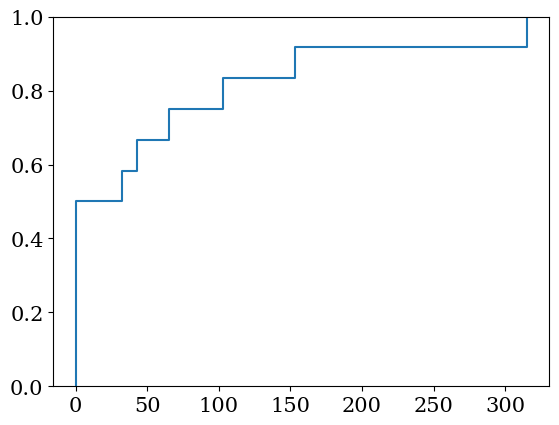

In [121]:
plt.ecdf(M_hs[ws2_i, ws2_j])

In [330]:
ws2_j_mid

np.int64(4)

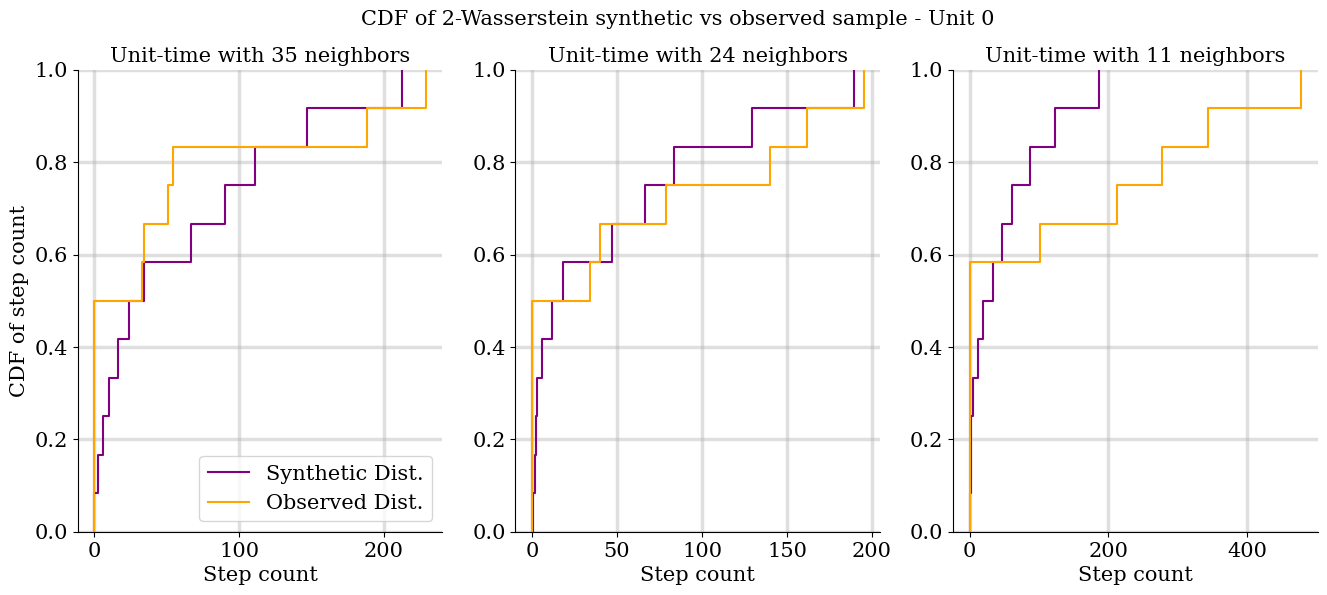

In [91]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(ws2_estimates[ws2_i, ws2_j].flatten(),color = "purple")
ax1.ecdf(M_hs[ws2_i, ws2_j].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with 35 neighbors")

ax2.ecdf(ws2_estimates[ws2_i_mid][ws2_j_mid].flatten(),color = "purple")
ax2.ecdf(M_hs[ws2_i_mid, ws2_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 24 neighbors")

ax3.ecdf(ws2_estimates[ws2_i_poor][ws2_j_poor].flatten(),color = "purple")
ax3.ecdf(M_hs[ws2_i_poor, ws2_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with 11 neighbors")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of 2-Wasserstein synthetic vs observed sample - Unit 0")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_ws2_nn_updated.pdf", bbox_inches = "tight")

In [162]:
M_hs[10].shape

(200, 12, 1)

In [171]:
pos_inds = np.nonzero((np.count_nonzero(M_hs.squeeze(axis = -1), axis = 2) > 10), np.nonzero())



2

In [61]:
random.seed(a=1)
high_nn_mmd_exp= np.nonzero((nn_mmd_exp[0] >= 30)) #& (np.count_nonzero(M_hs[10].squeeze(axis = -1), axis = 1) > 5))
rand_num = random.randrange(len(high_nn_mmd_exp[0]))
print(len(high_nn_mmd_exp[0]))
mmd_exp_i_high = 0 #high_nn_ws2[0][rand_num]
mmd_exp_j_high = high_nn_mmd_exp[0][rand_num]

nn_mmd_exp[mmd_exp_i_high, mmd_exp_j_high]


16


np.float64(31.0)

In [62]:
random.seed(a=2)
mid_nn_mmd_exp = np.nonzero((nn_mmd_exp[0] < 30) & (nn_mmd_exp[0] > 10))# & (np.count_nonzero(M_hs[10].squeeze(axis = -1), axis = 1) > 5))
print(len(mid_nn_mmd_exp[0]))
rand_num = random.randrange(len(mid_nn_mmd_exp[0]))
mmd_exp_i_mid = 0 #mid_nn_ws2[0][rand_num]
mmd_exp_j_mid = mid_nn_mmd_exp[0][rand_num]

nn_mmd_exp[mmd_exp_i_mid, mmd_exp_j_mid]

33


np.float64(26.0)

In [63]:
random.seed(a=1)
poor_nn_mmd_exp = np.nonzero((nn_mmd_exp[0] < 10))
print(len(poor_nn_mmd_exp[0]))
rand_num = random.randrange(len(poor_nn_mmd_exp[0]))
mmd_exp_i_poor = 0 #poor_nn_ws2[0][rand_num]
mmd_exp_j_poor = poor_nn_mmd_exp[0][rand_num]

nn_mmd_exp[mmd_exp_i_poor, mmd_exp_j_poor]

1


np.float64(8.0)

In [ ]:
save_ws2_high = ws2_j
save_ws2_mid = ws2_j_mid
save_ws2_poor = ws2_j_poor

# seeds: 365, 10, 200

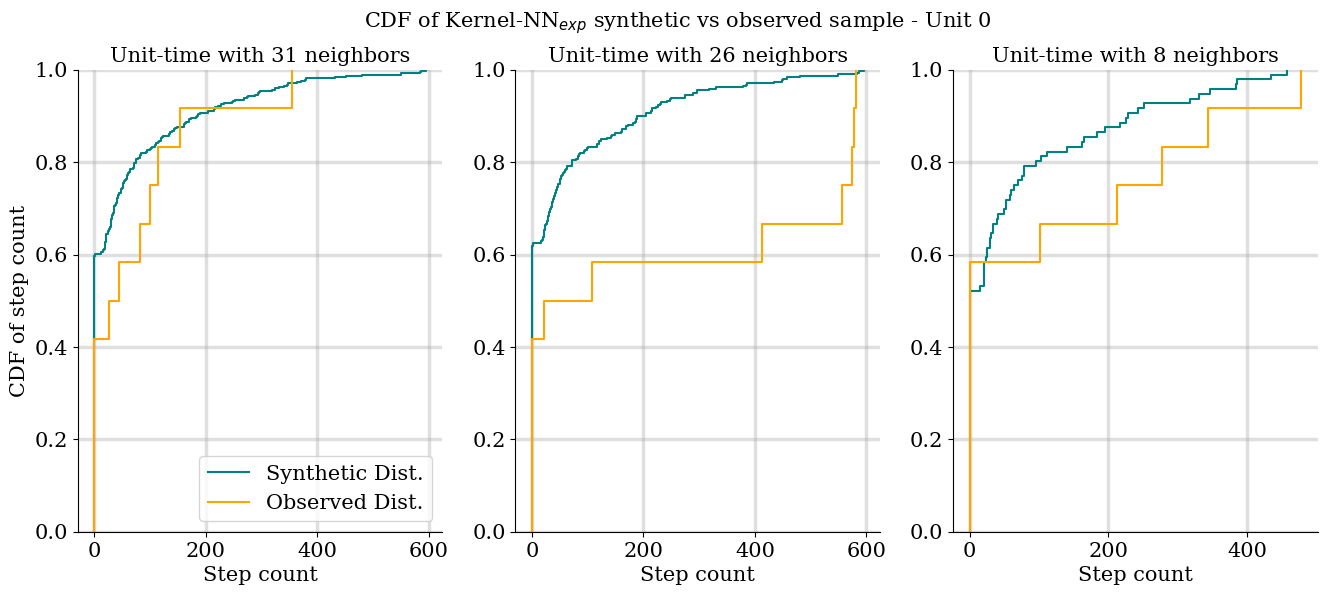

In [66]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(mmd_estimates_exp[mmd_exp_i_high][mmd_exp_j_high].flatten(),color = "teal")
ax1.ecdf(M_hs[mmd_exp_i_high, mmd_exp_j_high].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with 31 neighbors")

ax2.ecdf(mmd_estimates_exp[mmd_exp_i_mid][mmd_exp_j_mid].flatten(),color = "teal")
ax2.ecdf(M_hs[mmd_exp_i_mid, mmd_exp_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 26 neighbors")

ax3.ecdf(mmd_estimates_exp[mmd_exp_i_poor][mmd_exp_j_poor].flatten(),color = "teal")
ax3.ecdf(M_hs[mmd_exp_i_poor, mmd_exp_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with 8 neighbors")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Kernel-NN$_{exp}$ synthetic vs observed sample - Unit 0")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_mmd_exp_nn_updated.pdf", bbox_inches = "tight")

In [248]:
mmd_exp_j_mid

np.int64(27)

In [68]:
random.seed(a=265)
high_nn_mmd_sq= np.nonzero((nn_mmd_sq[0] >= 30)) #& (np.count_nonzero(M_hs[33].squeeze(axis = -1), axis = 1) > 5))
rand_num = random.randrange(len(high_nn_mmd_sq[0]))
print(len(high_nn_mmd_sq[0]))
mmd_sq_i_high = 0 #high_nn_ws2[0][rand_num]
mmd_sq_j_high = high_nn_mmd_sq[0][rand_num]

nn_mmd_sq[mmd_sq_i_high][mmd_sq_j_high]


35


np.float64(41.0)

In [94]:
random.seed(a=100)
mid_nn_mmd_sq = np.nonzero((nn_mmd_sq[0] < 30) & (nn_mmd_sq[0] > 20)) #& (np.count_nonzero(M_hs[33].squeeze(axis = -1), axis = 1) > 5))
print(len(mid_nn_mmd_sq[0]))
rand_num = random.randrange(len(mid_nn_mmd_sq[0]))
mmd_sq_i_mid = 0 #mid_nn_ws2[0][rand_num]
mmd_sq_j_mid = mid_nn_mmd_sq[0][rand_num]

nn_mmd_sq[mmd_sq_i_mid, mmd_sq_j_mid]

13


np.float64(25.0)

In [73]:
random.seed(a=10)
poor_nn_mmd_sq = np.nonzero((nn_mmd_sq[0] < 20))
print(len(poor_nn_mmd_sq[0]))
rand_num = random.randrange(len(poor_nn_mmd_sq[0]))
mmd_sq_i_poor = 0 #poor_nn_ws2[0][rand_num]
mmd_sq_j_poor = poor_nn_mmd_sq[0][rand_num]

nn_mmd_sq[mmd_sq_i_poor, mmd_sq_j_poor]

2


np.float64(13.0)

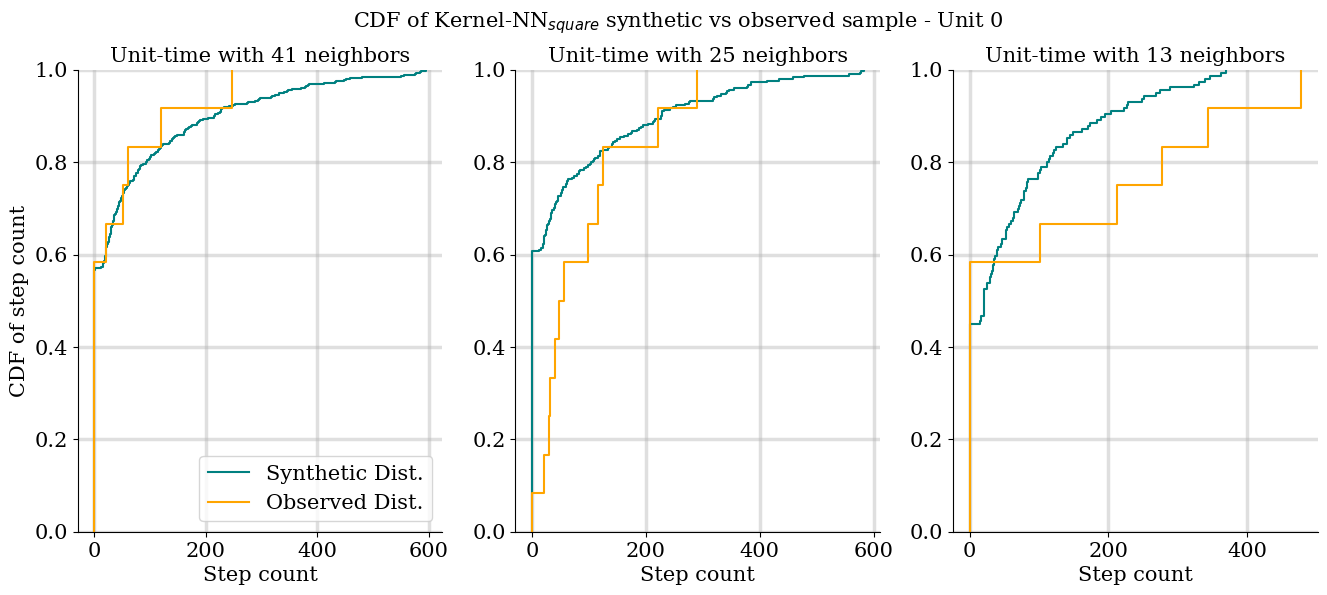

In [98]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (16, 6), ncols = 3)

ax1.ecdf(mmd_estimates_sq[mmd_sq_i_high][mmd_sq_j_high].flatten(),color = "teal")
ax1.ecdf(M_hs[mmd_sq_i_high, mmd_sq_j_high].flatten(), color="orange")
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("CDF of step count")
ax1.set_title("Unit-time with 41 neighbors")

ax2.ecdf(mmd_estimates_sq[mmd_sq_i_mid][mmd_sq_j_mid].flatten(),color = "teal")
ax2.ecdf(M_hs[mmd_sq_i_mid, mmd_sq_j_mid].flatten(), color="orange")
ax2.set_xlabel("Step count")
ax2.set_title("Unit-time with 25 neighbors")

ax3.ecdf(mmd_estimates_sq[mmd_sq_i_poor][mmd_sq_j_poor].flatten(),color = "teal")
ax3.ecdf(M_hs[mmd_sq_i_poor, mmd_sq_j_poor].flatten(), color="orange")
ax3.set_xlabel("Step count")
ax3.set_title("Unit-time with 13 neighbors")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)

fig.suptitle("CDF of Kernel-NN$_{square}$ synthetic vs observed sample - Unit 0")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("cdf_mmd_sq_nn_updated.pdf", bbox_inches = "tight")

## Log-Transform KDE Graphs

In [2]:
import scipy
import seaborn as sns

import numpy as np

In [99]:
mmd_estimates_exp = np.load("../data_checkpoints/mmd_exp_estimates_v17.npy", allow_pickle = True)
mmd_estimates_sq = np.load("../data_checkpoints/mmd_sq_estimates_v17.npy", allow_pickle = True)
ws2_estimates = np.load("../data_checkpoints/ws2_estimates_v17.npy")

mmd_estimates_exp_log = np.load("../data_checkpoints/mmd_exp_estimates_v16_log.npy", allow_pickle = True)
mmd_estimates_sq_log = np.load("../data_checkpoints/mmd_sq_estimates_v16_log.npy", allow_pickle = True)
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v16_log.npy")

nn_ws2_log = np.load('../data_checkpoints/ws2_nncount_v16_log.npy')
nn_mmd_exp_log = np.load('../data_checkpoints/mmd_exp_nncount_v16_log.npy')
nn_mmd_sq_log = np.load('../data_checkpoints/mmd_sq_nncount_v16_log.npy')

nn_ws2 = np.load('../data_checkpoints/ws2_nncount_v17.npy')
nn_mmd_exp = np.load('../data_checkpoints/mmd_exp_nncount_v17.npy')
nn_mmd_sq = np.load('../data_checkpoints/mmd_sq_nncount_v17.npy')

M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

M_hs_log = np.log(M_hs + 1)

N, T, n, d = M_hs.shape

First, we graph the KDE of non-log transformed data alongside the their estimates.

In [238]:
np.nonzero(nn_ws2 > 20)[1]

array([  4,  12,  22,  27,  30,  33,  36,  37,  38,  42,  44,  56,  59,
        60,  65,  72,  78,  80,  83,  87,  92, 106, 107, 109, 112, 113,
       116, 127, 129, 132, 137, 139, 145, 146, 147, 148, 151, 154, 155,
       164, 171, 172, 174,   4,  12,  17,  22,  26,  39,  47,  49,  56,
        57,  73,  78,  94,  99, 101, 105, 116, 129, 140, 143, 154, 166,
       119, 121, 124, 152, 161, 172, 176, 187,  17,  20,  26,  51,  55,
        57,  92, 100, 105, 110, 146, 165, 170, 183, 194,   7,   9,  10,
        19,  20,  21,  30,  35,  41,  43,  46,  59,  65,  68,  75,  81,
        85,  87,  20,  55,  68,  98,  16,  17,  49,  59,  60,  62,  66,
        70,  75,  76,  77,  78,  92,  99, 105, 106, 109, 115, 116, 117,
       119, 127, 133, 137, 151, 163, 164, 165, 167, 170, 195, 197, 198,
         4,   9,  16,  27,  35,  39,  47,  48,  62,  64,  66,  68,  69,
        75,  80,  81,  83,  89,  92,  94,  99,   6,   8,   9,  10,  11,
        17,  21,  24,  26,  33,  35,  46,  54,  55,  57,  58,  6

In [323]:
nn_ws2_log

array([[nan,  8., nan, ..., nan, nan, nan],
       [nan, 11., nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., 35., 27., nan],
       [nan, nan, nan, ..., nan, nan, nan]])

In [324]:
np.nonzero(~np.isnan(nn_ws2_log))

(array([ 0,  0,  0, ..., 36, 36, 36]),
 array([  1,   4,   6, ..., 165, 177, 194]))

In [106]:
ws2_estimates = np.load("../data_checkpoints/ws2_estimates_v17.npy")
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v18_log.npy")

mmd_estimates_exp = np.load("../data_checkpoints/mmd_exp_estimates_v17.npy", allow_pickle=True)
mmd_estimates_exp_log = np.load("../data_checkpoints/mmd_exp_estimates_v18_log.npy", allow_pickle=True)

mmd_estimates_sq = np.load("../data_checkpoints/mmd_sq_estimates_v17.npy", allow_pickle=True)
mmd_estimates_sq_log = np.load("../data_checkpoints/mmd_sq_estimates_v18_log.npy", allow_pickle=True)

ws2_neighbors = np.load("../data_checkpoints/ws2_full_neighbors_v17.npy", allow_pickle=True)
ws2_neighbors_log = np.load("../data_checkpoints/ws2_full_neighbors_v18_log.npy", allow_pickle=True)

mmd_exp_neighbors = np.load("../data_checkpoints/mmd_exp_full_neighbors_v17.npy", allow_pickle=True)
mmd_exp_neighbors_log = np.load("../data_checkpoints/mmd_exp_full_neighbors_v18_log.npy", allow_pickle=True)

mmd_sq_neighbors = np.load("../data_checkpoints/mmd_sq_full_neighbors_v17.npy", allow_pickle=True)
mmd_sq_neighbors_log = np.load("../data_checkpoints/mmd_sq_full_neighbors_v18_log.npy", allow_pickle=True)

nn_ws2 = np.load("../data_checkpoints/ws2_nncount_v17.npy")

In [116]:
# ws2_unit = np.nonzero(nn_ws2_log > 20)[0][0]
# ws2_time = np.nonzero(nn_ws2_log > 20)[1][0]
# ws2_time

ws2_unit = 7 #np.nonzero(~np.isnan(nn_ws2_log))[0][1]
ws2_time = 62 #np.nonzero(~np.isnan(nn_ws2_log))[1][1]
#ws2_time
# ws2_unit = np.nonzero(nn_ws2 > 20)[0][150]
# ws2_time = np.nonzero(nn_ws2 > 20)[1][150]
mmd_exp_unit = ws2_unit
mmd_exp_time = ws2_time

mmd_sq_unit = ws2_unit
mmd_sq_time = ws2_time


In [475]:
ws2_time
# 0, 4
# 1, 4
# 7, 62

np.int64(62)

Text(0.5, 0.98, 'KDE of 2-Wasserstein synthetic vs observed sample')

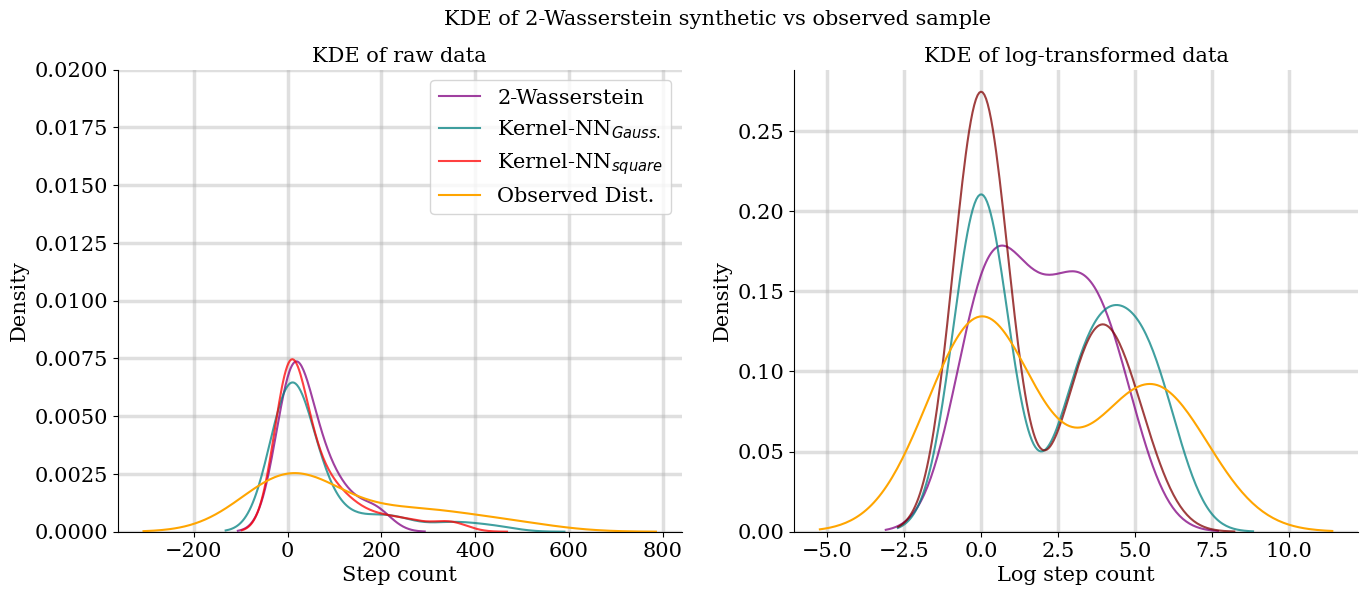

In [108]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1, alpha = 0.75)
sns.kdeplot(mmd_estimates_exp[ws2_unit][ws2_time].flatten(), color = "teal", ax = ax1, alpha = 0.75)
sns.kdeplot(mmd_estimates_sq[ws2_unit][ws2_time].flatten(), color = "red", ax = ax1, alpha = 0.75)

sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)


ax1.legend(["2-Wasserstein"] + ["Kernel-NN$_{Gauss.}$"] + ["Kernel-NN$_{square}$"] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of raw data")

sns.kdeplot(ws2_estimates_log[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax2, alpha = 0.75)
sns.kdeplot(mmd_estimates_exp_log[ws2_unit][ws2_time].flatten(), color = "teal", ax = ax2, alpha = 0.75)
sns.kdeplot(mmd_estimates_sq_log[ws2_unit][ws2_time].flatten(), color = "maroon", ax = ax2, alpha = 0.75)
sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)


ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
ax1.set_ylim(0, 0.02)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of 2-Wasserstein synthetic vs observed sample")
#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("kde_ws2_unit7time62.pdf", bbox_inches = "tight")

[  9  16  27  35  39  43  45  64  66  75  80  81  83  98  99 125 126 127
 131 138 148 166 167 184]


C:\Users\Caleb\AppData\Local\Temp\ipykernel_35588\2904914147.py:20: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_35588\2904914147.py:56: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_35588\2904914147.py:87: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax6, alpha= 0.2)


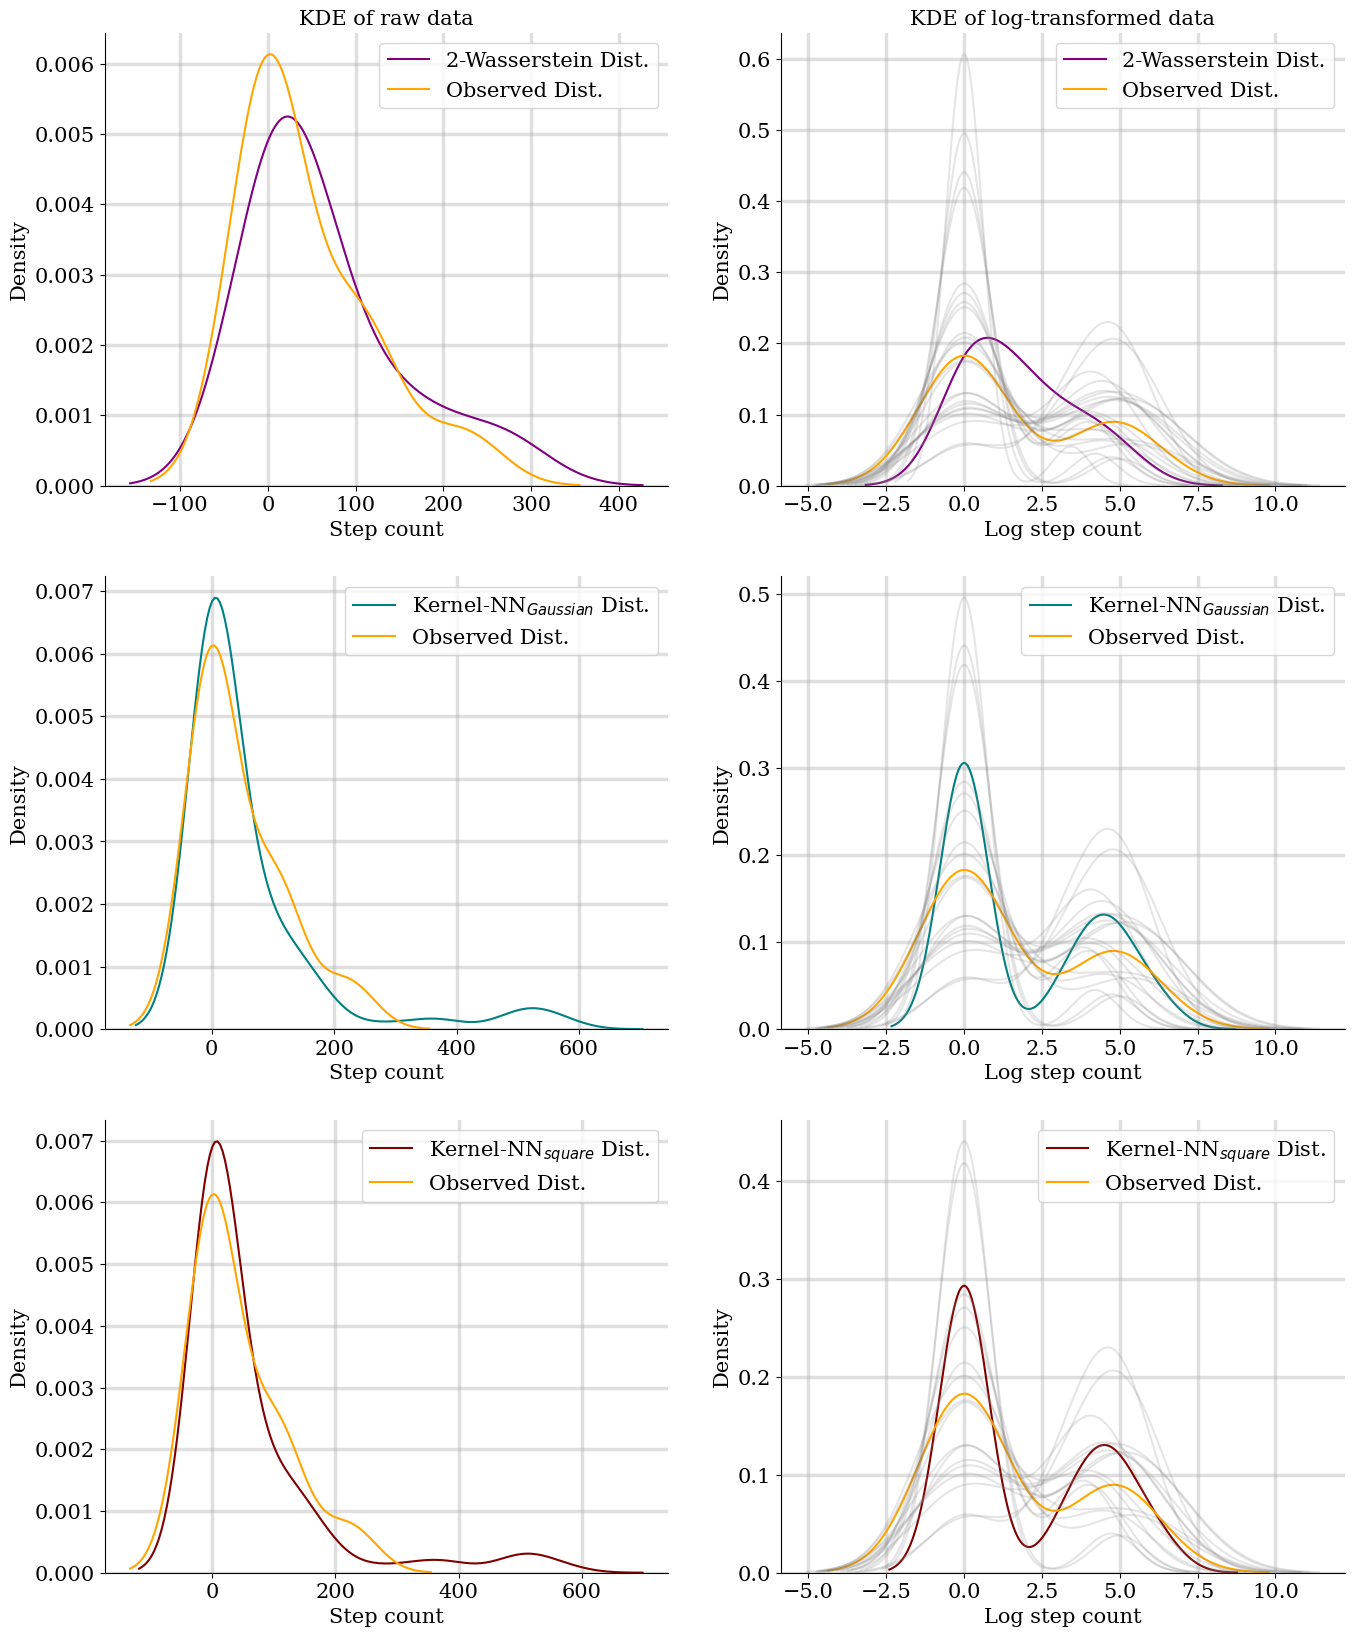

In [118]:
fig, ((ax1, ax2), (ax3, ax4), (ax5, ax6)) = plt.subplots(figsize = (16, 20), ncols = 2, nrows = 3)

sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1)
sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)

print(ws2_neighbors_log[ws2_unit][ws2_time][0])

# for j in ws2_neighbors[ws2_unit][ws2_time][0]:
#   sns.kdeplot(M_hs[ws2_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.2)


ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of raw data")

sns.kdeplot(ws2_estimates_log[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax2)
sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)

for j in ws2_neighbors_log[ws2_unit][ws2_time][0]:
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)

ax2.legend(["2-Wasserstein Dist."] + ["Observed Dist."])
ax1.legend(["2-Wasserstein Dist."] + ["Observed Dist."])

ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)
#ax1.set_ylim(0, 0.03)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax3)
sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax3)

# for j in mmd_exp_neighbors[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax3, alpha= 0.2)


ax3.set_xlabel("Step count")
ax3.set_ylabel("Density")
#ax3.set_title("KDE of data")

#ax3.set_ylim(0, 0.03)
#ax2.set_ylim(0, 0.4)
#ax4.set_ylim(0, 0.4)

sns.kdeplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax4)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax4)

for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
  sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)

ax4.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])
ax3.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])

ax4.set_xlabel("Log step count")
#ax4.set_title("KDE of log-transformed data")

ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
ax3.grid(True, alpha=0.4)


ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.grid(True, alpha=0.4)

sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax5)
sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax5)

ax5.set_xlabel("Step count")
ax5.set_ylabel("Density")
#ax5.set_title("KDE of data")

# for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax5, alpha= 0.2)

sns.kdeplot(mmd_estimates_sq_log[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon",ax = ax6)
sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax6)

for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
  sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax6, alpha= 0.2)

ax6.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])
ax5.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])

ax6.set_xlabel("Log step count")
#ax6.set_title("KDE of log-transformed data")

ax5.spines['top'].set_visible(False)
ax5.spines['right'].set_visible(False)
ax5.grid(True, alpha=0.4)

#ax5.set_ylim(0, 0.03)

ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)
ax6.grid(True, alpha=0.4)


#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_alldnn_unit7time62_updated.pdf", bbox_inches = "tight")

In [7]:
ws2_estimates_log = np.load('../data_checkpoints/ws2_estimates_v23_log_backfront.npy')
mmd_estimates_exp_log = np.load('../data_checkpoints/mmd_exp_estimates_v23_log_backfront.npy', allow_pickle = True)
mmd_estimates_sq_log = np.load('../data_checkpoints/mmd_sq_estimates_v23_log_backfront.npy', allow_pickle = True)

ws2_neighbors_log = np.load('../data_checkpoints/ws2_full_neighbors_v23_log_backfront.npy', allow_pickle = True)
mmd_exp_neighbors_log = np.load('../data_checkpoints/mmd_exp_full_neighbors_v23_log_backfront.npy', allow_pickle = True)
mmd_sq_neighbors_log = np.load('../data_checkpoints/mmd_sq_full_neighbors_v23_log_backfront.npy', allow_pickle=True)

In [8]:
import seaborn as sns

In [22]:
ws2_estimates_log.shape

(37, 200, 12)

In [30]:
counter = 0
for i in range(0, 37):
  for j in range(0, 200):
    if A_hs[i, j] == 1:
      if dnn.sqmmd_est2(mmd_estimates_exp_log[i][j], M_hs_log[i][j], kernel = "exponential") < 0.002 and np.nanmean(M_hs_log[i][j]) != 0:
        print(str(i) + " " + str(j))
        counter += 1

print(counter)

0 4
0 38
0 72
0 79
0 96
0 106
0 107
0 112
0 137
0 145
0 151
1 17
1 22
1 49
1 56
1 57
1 67
1 81
1 101
1 105
1 143
2 46
2 57
2 67
2 85
2 121
2 124
2 126
2 189
3 9
3 52
3 62
3 83
3 106
3 146
3 187
3 194
4 10
4 19
4 20
4 41
4 43
4 46
4 105
4 112
4 133
4 150
4 174
5 37
5 55
5 68
5 71
5 77
5 82
5 88
5 115
5 125
5 131
5 142
5 149
5 166
6 17
6 62
6 72
6 77
6 109
6 133
6 138
7 6
7 62
7 69
7 75
7 81
7 83
7 104
7 126
7 138
7 142
7 143
7 154
7 157
7 159
7 167
7 186
7 199
8 9
8 11
8 64
8 113
8 116
8 127
8 142
9 5
9 18
9 23
9 41
9 89
9 164
9 187
9 188
9 189
9 195
10 8
10 23
10 28
10 30
10 53
10 57
10 58
10 66
10 68
10 72
10 93
10 94
10 114
10 116
10 131
10 137
10 157
10 167
10 179
11 3
11 16
11 17
11 25
11 33
11 52
11 58
11 74
11 84
11 100
11 147
11 162
11 172
11 197
12 19
12 20
12 40
12 66
12 124
12 126
12 177
12 183
13 17
13 40
13 44
13 60
13 139
13 142
13 154
14 17
14 24
14 52
14 56
14 136
14 147
15 16
15 24
15 30
15 53
15 60
15 80
15 89
15 129
15 149
15 172
15 184
15 197
16 6
16 11
16 18
16 30
1

In [9]:
# 0, 4
# 1, 4
# 7, 62
ws2_unit = 1
ws2_time = 17

mmd_exp_unit = ws2_unit
mmd_exp_time = ws2_time

mmd_sq_unit = ws2_unit
mmd_sq_time = ws2_time


In [10]:
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

M_hs_log = np.log(M_hs + 1)

In [152]:
np.nonzero(A_hs[0] == 1)

(array([  1,   4,   6,  11,  12,  22,  27,  30,  33,  36,  37,  38,  42,
         43,  44,  56,  59,  60,  65,  72,  78,  79,  80,  83,  87,  88,
         92,  96, 106, 107, 109, 112, 113, 116, 127, 129, 132, 137, 139,
        145, 146, 147, 148, 151, 154, 155, 164, 171, 172, 174]),)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_32544\2423039096.py:20: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_32544\2423039096.py:20: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_32544\2423039096.py:20: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_32544\2423039096.py:56: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kde

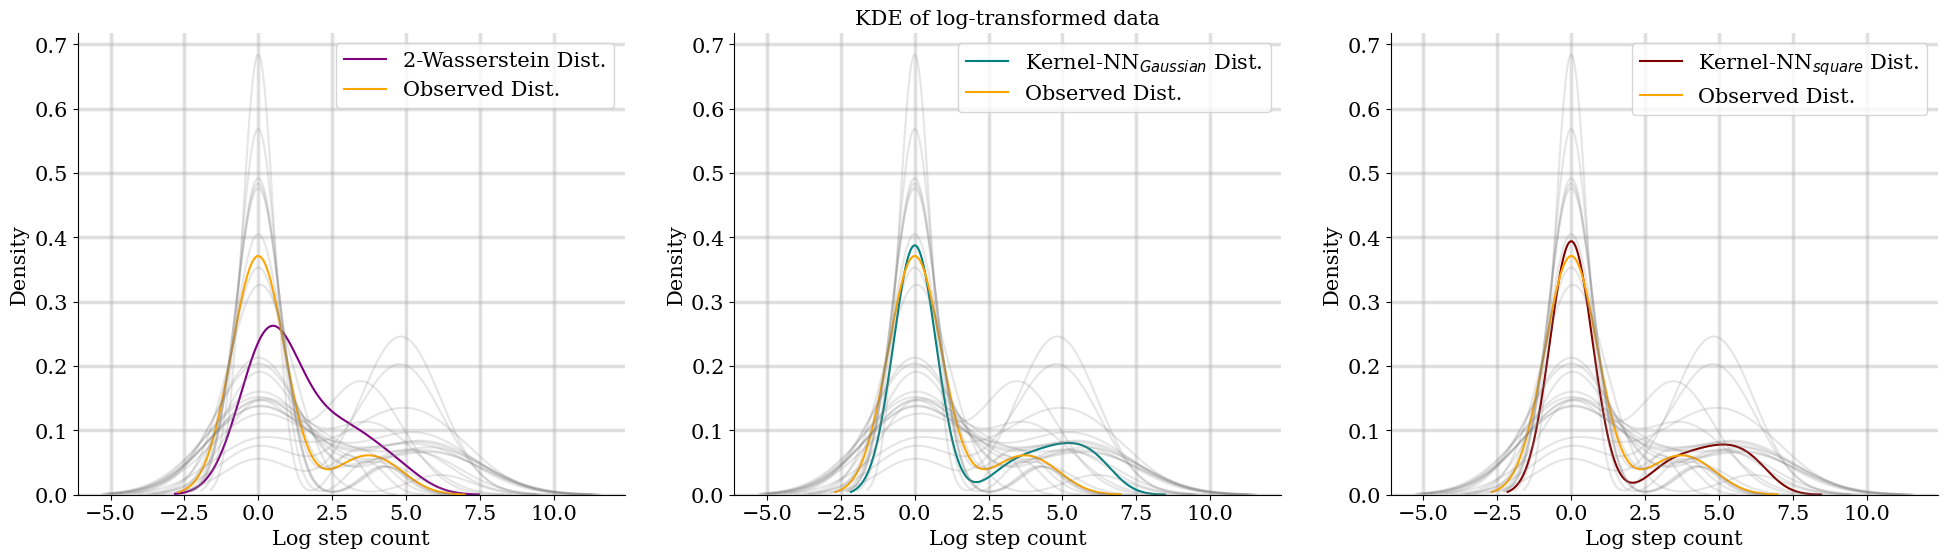

In [13]:
fig, ((ax2), (ax4), (ax6)) = plt.subplots(figsize = (24, 6), ncols = 3, nrows = 1)

# sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1)
# sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)

# print(ws2_neighbors_log[ws2_unit][ws2_time][0])

# # for j in ws2_neighbors[ws2_unit][ws2_time][0]:
# #   sns.kdeplot(M_hs[ws2_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.2)


# ax1.set_xlabel("Step count")
# ax1.set_ylabel("Density")
# ax1.set_title("KDE of raw data")

sns.kdeplot(ws2_estimates_log[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax2)
sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)

for j in ws2_neighbors_log[ws2_unit][ws2_time][0]:
  sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)

ax2.legend(["2-Wasserstein Dist."] + ["Observed Dist."])
#ax1.legend(["2-Wasserstein Dist."] + ["Observed Dist."])

ax2.set_xlabel("Log step count")
#ax2.set_title("KDE of log-transformed data")

# ax1.spines['top'].set_visible(False)
# ax1.spines['right'].set_visible(False)
# ax1.grid(True, alpha=0.4)
# #ax1.set_ylim(0, 0.03)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

# sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax3)
# sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax3)

# for j in mmd_exp_neighbors[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax3, alpha= 0.2)


# ax3.set_xlabel("Step count")
# ax3.set_ylabel("Density")
#ax3.set_title("KDE of data")

#ax3.set_ylim(0, 0.03)
#ax2.set_ylim(0, 0.4)
#ax4.set_ylim(0, 0.4)

sns.kdeplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax4)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax4)

for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
  sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)

ax4.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])
#ax3.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])

ax4.set_xlabel("Log step count")
ax4.set_title("KDE of log-transformed data")

# ax3.spines['top'].set_visible(False)
# ax3.spines['right'].set_visible(False)
# ax3.grid(True, alpha=0.4)


ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.grid(True, alpha=0.4)

# sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax5)
# sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax5)

# ax5.set_xlabel("Step count")
# ax5.set_ylabel("Density")
#ax5.set_title("KDE of data")

# for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax5, alpha= 0.2)

sns.kdeplot(mmd_estimates_sq_log[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon",ax = ax6)
sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax6)

for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
  sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax6, alpha= 0.2)

ax6.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])
#ax5.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])

ax6.set_xlabel("Log step count")
#ax6.set_title("KDE of log-transformed data")

# ax5.spines['top'].set_visible(False)
# ax5.spines['right'].set_visible(False)
# ax5.grid(True, alpha=0.4)

#ax5.set_ylim(0, 0.03)

ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)
ax6.grid(True, alpha=0.4)


#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("kde_alldnn_unit7time62_updated.pdf", bbox_inches = "tight")

In [ ]:
# 0, 4
# 0, 38

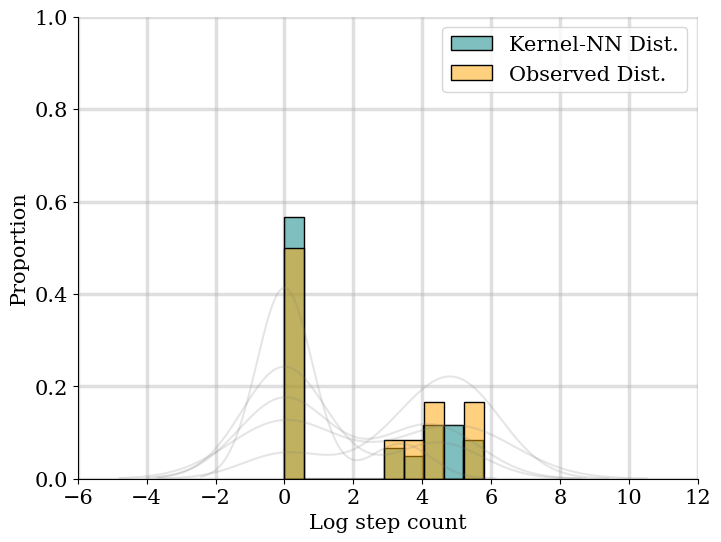

In [96]:
ws2_unit = 5
ws2_time = 88

mmd_exp_unit = ws2_unit
mmd_exp_time = ws2_time

fig, ax4 = plt.subplots(figsize = (8, 6), ncols = 1, nrows = 1)

sns.histplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].squeeze(), color = "teal", alpha = 0.5, stat="proportion", bins = 10)
sns.histplot(M_hs_log[mmd_exp_unit][mmd_exp_time].squeeze(), color = "orange", alpha = 0.5, stat="proportion", bins = 10)

ax4.legend(["Kernel-NN Dist."] + ["Observed Dist."])
#sns.kdeplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax4)
#sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax4)

for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
   sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)
#ax4.legend(["Target Dist."])

#ax3.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])

ax4.set_xlabel("Log step count")

ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.grid(True, alpha=0.4)

ax4.set_ylim(0, 1)
ax4.set_xlim(-6, 12)


#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_kernel_gaussian_unit5time88.pdf", bbox_inches = "tight")

In [18]:
A_hs[1, 4]

np.float64(1.0)

In [28]:
A_hs_inv = A_hs.copy()
A_hs_inv[A_hs == 1] = 0
A_hs_inv[A_hs == 0] = 1

# A_hs_inv[0,4] = 0
#dists_ws2 = dnn.get_col_differences(M_hs_log, A_hs_inv, "wasserstein2", kernel = None)
dists_mmd_exp = dnn.get_col_differences(M_hs_log, A_hs_inv, "mmd", kernel = "exponential")
#dists_mmd_sq = dnn.get_col_differences(M_hs_log, A_hs_inv, "mmd", kernel = "square")

# eta_star_ws2, _ = cv_dnn.search_eta(
#   M_hs_log, 
#   A_hs_inv, 
#   k = 5,  
#   row = 0,
#   col_dists = dists_ws2,
#   est_func = dnn.estimate_row, 
#   metric = "wasserstein2",
#   range_min = 0,
#   range_max = 50
#   )

eta_star_mmd_exp, _ = cv_dnn.search_eta(
  M_hs_log, 
  A_hs_inv, 
  k = 5,
  row = 0,  
  col_dists = dists_mmd_exp,
  est_func = dnn.estimate_row, 
  metric = "mmd",
  range_min = 0,
  range_max = 1.9,
  kernel = "exponential"
  )

# eta_star_mmd_sq, _ = cv_dnn.search_eta(
#   M_hs_log, 
#   A_hs_inv, 
#   k = 5,  
#   row = 0,
#   col_dists = dists_mmd_sq,
#   est_func = dnn.estimate_row, 
#   metric = "mmd",
#   range_min = 0,
#   range_max = 2500,
#   kernel = "square"
#   )

#ws2_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [4], dists_ws2, eta_star_ws2)
mmd_exp_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [4], dists_mmd_exp, eta_star_mmd_exp)
#mmd_sq_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [4], dists_mmd_sq, eta_star_mmd_sq) 



  0%|          | 0/200 [00:00<?, ?trial/s, best loss=?]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:60: RuntimeWarning: invalid value encountered in subtract
  kXX = np.exp(-0.5 * (dXX_mm + np.transpose(dXX_mm) - 2 * XX))



  2%|▏         | 3/200 [00:18<19:22,  5.90s/trial, best loss: 0.1696026017358321]

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:44: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2))  # m by n matrix with x_i^Ty_j



100%|██████████| 200/200 [13:29<00:00,  4.05s/trial, best loss: 0.006727610344662514]


In [137]:
np.nonzero(A_hs[0] == 1)

(array([  1,   4,   6,  11,  12,  22,  27,  30,  33,  36,  37,  38,  42,
         43,  44,  56,  59,  60,  65,  72,  78,  79,  80,  83,  87,  88,
         92,  96, 106, 107, 109, 112, 113, 116, 127, 129, 132, 137, 139,
        145, 146, 147, 148, 151, 154, 155, 164, 171, 172, 174]),)

In [29]:
ws2_unit = 0
ws2_time = 12

mmd_exp_unit = ws2_unit
mmd_exp_time = ws2_time

mmd_sq_unit = ws2_unit
mmd_sq_time = ws2_time


In [30]:
#ws2_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [12], dists_ws2, eta_star_ws2)
mmd_exp_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [12], dists_mmd_exp, eta_star_mmd_exp)
#mmd_sq_est = dnn.estimate_row(M_hs_log, A_hs_inv, 0, [12], dists_mmd_sq, eta_star_mmd_sq) 

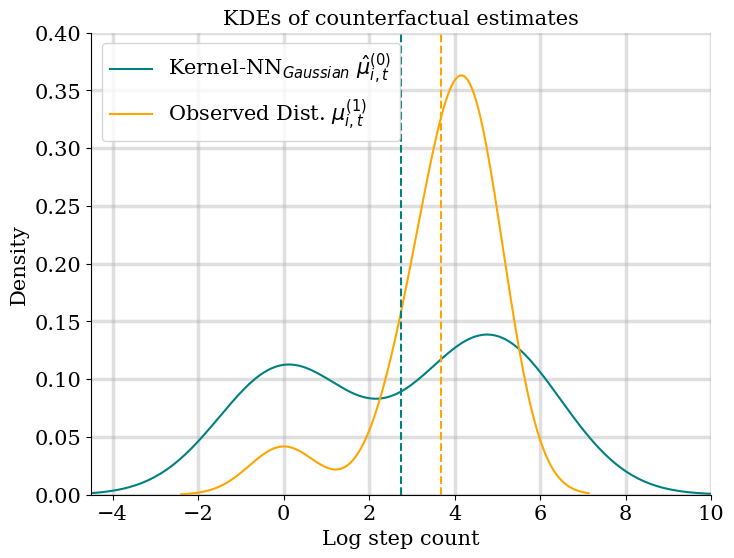

In [41]:
fig, ax4 = plt.subplots(figsize = (8, 6), ncols = 1, nrows = 1)

# sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1)
# sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)

# print(ws2_neighbors_log[ws2_unit][ws2_time][0])

# # for j in ws2_neighbors[ws2_unit][ws2_time][0]:
# #   sns.kdeplot(M_hs[ws2_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.2)


# ax1.set_xlabel("Step count")
# ax1.set_ylabel("Density")
# ax1.set_title("KDE of raw data")

# sns.kdeplot(ws2_est.flatten(),color = "purple", ax = ax2)
# sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)

# for j in ws2_neighbors_log[ws2_unit][ws2_time][0]:
#   sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)

# ax2.legend(["2-Wasserstein $\hat{\mu}_{i, t}^{(0)}$"] + ["Observed Dist."])
# #ax1.legend(["2-Wasserstein Dist."] + ["Observed Dist."])

# ax2.set_xlabel("Log step count")
# #ax2.set_title("KDE of log-transformed data")

# ax1.spines['top'].set_visible(False)
# ax1.spines['right'].set_visible(False)
# ax1.grid(True, alpha=0.4)
# #ax1.set_ylim(0, 0.03)

# ax2.spines['top'].set_visible(False)
# ax2.spines['right'].set_visible(False)
# ax2.grid(True, alpha=0.4)

# sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax3)
# sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax3)

# for j in mmd_exp_neighbors[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax3, alpha= 0.2)


# ax3.set_xlabel("Step count")
# ax3.set_ylabel("Density")
#ax3.set_title("KDE of data")

#ax3.set_ylim(0, 0.03)
#ax2.set_ylim(0, 0.4)
#ax4.set_ylim(0, 0.4)



sns.kdeplot(mmd_exp_est.flatten(),color = "teal", ax = ax4)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax4)

# for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)

ax4.legend(["Kernel-NN$_{Gaussian}$ $\hat{\mu}_{i, t}^{(0)}$"] + ["Observed Dist. $\mu_{i, t}^{(1)}$"])
#ax4.legend(["Observed Dist. $\mu_{i, t}^{(1)}$"])
#ax3.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])

ax4.set_xlabel("Log step count")
ax4.set_title("KDEs of counterfactual estimates")

# ax3.spines['top'].set_visible(False)
# ax3.spines['right'].set_visible(False)
# ax3.grid(True, alpha=0.4)


ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.grid(True, alpha=0.4)

ax4.set_ylim(0, 0.40)
ax4.set_xlim(-4.5, 10)

# sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax5)
# sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax5)

# ax5.set_xlabel("Step count")
# ax5.set_ylabel("Density")
#ax5.set_title("KDE of data")

# for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax5, alpha= 0.2)

# sns.kdeplot(mmd_sq_est.flatten(),color = "maroon",ax = ax6)
# sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax6)

# # for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
# #   sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax6, alpha= 0.2)

# ax6.legend(["Kernel-NN$_{square}$ $\hat{\mu}_{i, t}^{(0)}$ "] + ["Observed Dist. "])
# #ax5.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])

# ax6.set_xlabel("Log step count")
#ax6.set_title("KDE of log-transformed data")

# ax5.spines['top'].set_visible(False)
# ax5.spines['right'].set_visible(False)
# ax5.grid(True, alpha=0.4)

#ax5.set_ylim(0, 0.03)

# ax6.spines['top'].set_visible(False)
# ax6.spines['right'].set_visible(False)
# ax6.grid(True, alpha=0.4)
ax4.axvline(np.nanmean(mmd_exp_est.flatten()), color='teal', linestyle = "--") # vertical
ax4.axvline(np.nanmean(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten()), color='orange', linestyle = "--") # horizontal

#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("kde_alldnn_unit7time62_updated.pdf", bbox_inches = "tight")

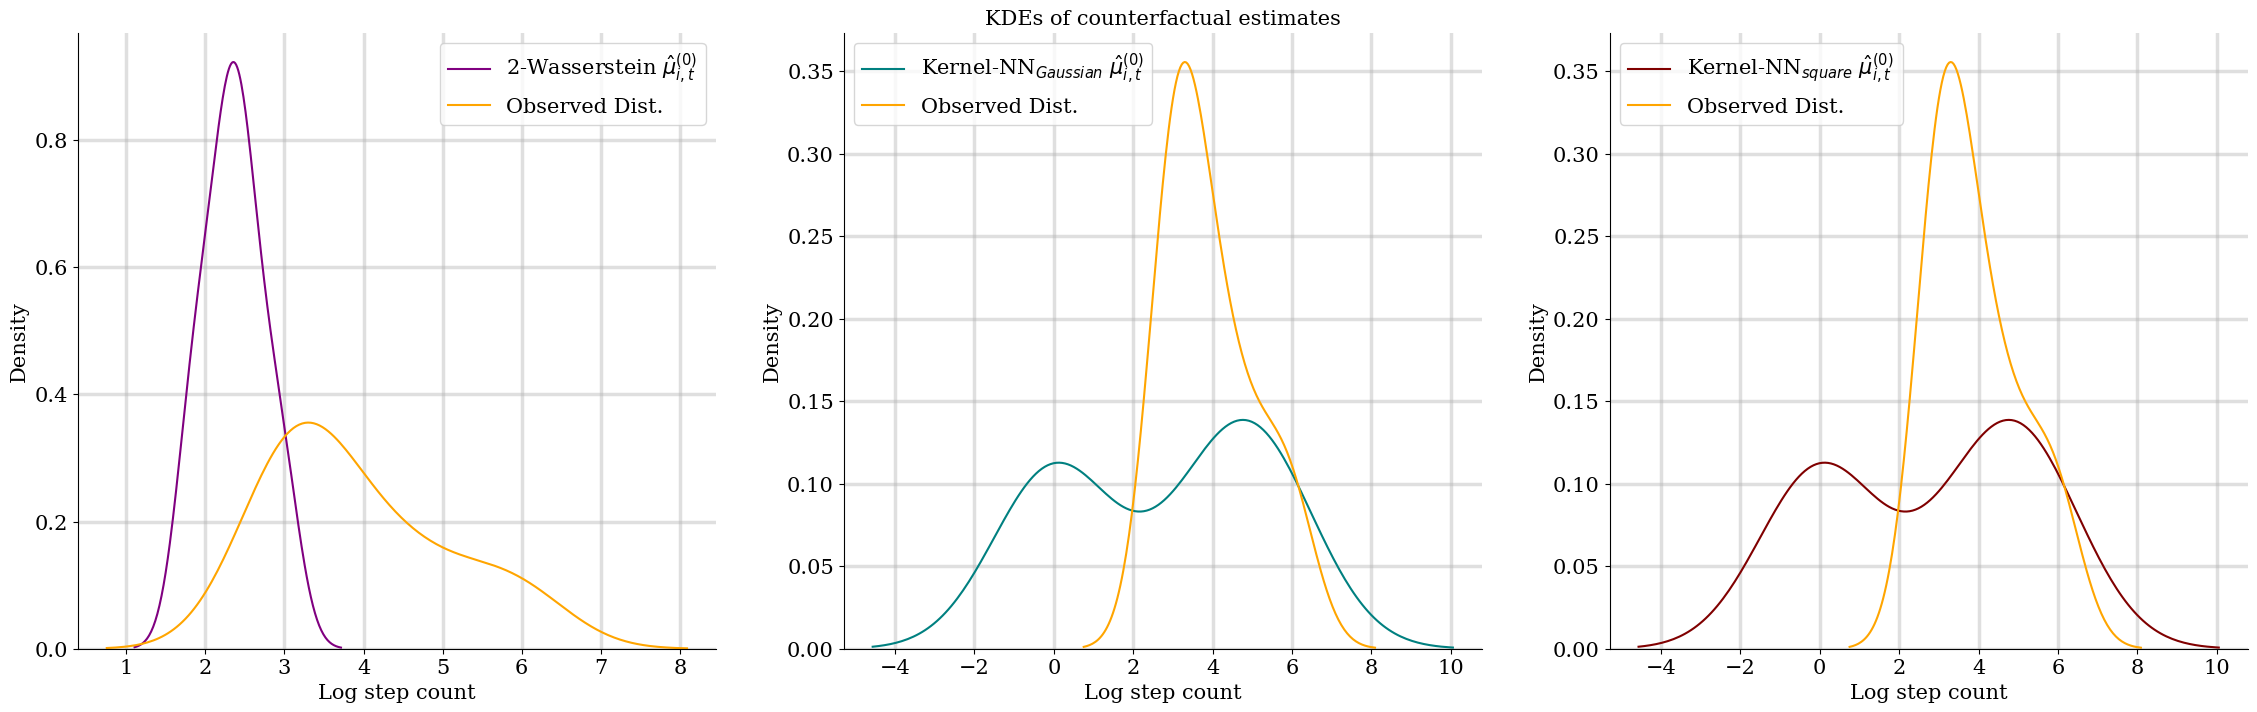

In [170]:
fig, ((ax2), (ax4), (ax6)) = plt.subplots(figsize = (28, 8), ncols = 3, nrows = 1)

# sns.kdeplot(ws2_estimates[ws2_unit][ws2_time].flatten(),color = "purple", ax = ax1)
# sns.kdeplot(M_hs[ws2_unit, ws2_time].flatten(), color="orange", ax = ax1)

# print(ws2_neighbors_log[ws2_unit][ws2_time][0])

# # for j in ws2_neighbors[ws2_unit][ws2_time][0]:
# #   sns.kdeplot(M_hs[ws2_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.2)


# ax1.set_xlabel("Step count")
# ax1.set_ylabel("Density")
# ax1.set_title("KDE of raw data")

sns.kdeplot(ws2_est.flatten(),color = "purple", ax = ax2)
sns.kdeplot(M_hs_log[ws2_unit, ws2_time].flatten(), color="orange", ax = ax2)

# for j in ws2_neighbors_log[ws2_unit][ws2_time][0]:
#   sns.kdeplot(M_hs_log[ws2_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.2)

ax2.legend(["2-Wasserstein $\hat{\mu}_{i, t}^{(0)}$"] + ["Observed Dist."])
#ax1.legend(["2-Wasserstein Dist."] + ["Observed Dist."])

ax2.set_xlabel("Log step count")
#ax2.set_title("KDE of log-transformed data")

# ax1.spines['top'].set_visible(False)
# ax1.spines['right'].set_visible(False)
# ax1.grid(True, alpha=0.4)
# #ax1.set_ylim(0, 0.03)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)

# sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax3)
# sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax3)

# for j in mmd_exp_neighbors[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax3, alpha= 0.2)


# ax3.set_xlabel("Step count")
# ax3.set_ylabel("Density")
#ax3.set_title("KDE of data")

#ax3.set_ylim(0, 0.03)
#ax2.set_ylim(0, 0.4)
#ax4.set_ylim(0, 0.4)

sns.kdeplot(mmd_exp_est.flatten(),color = "teal", ax = ax4)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax4)

# for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
#   sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax4, alpha= 0.2)

ax4.legend(["Kernel-NN$_{Gaussian}$ $\hat{\mu}_{i, t}^{(0)}$"] + ["Observed Dist."])
#ax3.legend(["Kernel-NN$_{Gaussian}$ Dist."] + ["Observed Dist."])

ax4.set_xlabel("Log step count")
ax4.set_title("KDEs of counterfactual estimates")

# ax3.spines['top'].set_visible(False)
# ax3.spines['right'].set_visible(False)
# ax3.grid(True, alpha=0.4)


ax4.spines['top'].set_visible(False)
ax4.spines['right'].set_visible(False)
ax4.grid(True, alpha=0.4)

# sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax5)
# sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax5)

# ax5.set_xlabel("Step count")
# ax5.set_ylabel("Density")
#ax5.set_title("KDE of data")

# for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax5, alpha= 0.2)

sns.kdeplot(mmd_sq_est.flatten(),color = "maroon",ax = ax6)
sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax6)

# for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax6, alpha= 0.2)

ax6.legend(["Kernel-NN$_{square}$ $\hat{\mu}_{i, t}^{(0)}$ "] + ["Observed Dist. "])
#ax5.legend(["Kernel-NN$_{square}$ Dist."] + ["Observed Dist."])

ax6.set_xlabel("Log step count")
#ax6.set_title("KDE of log-transformed data")

# ax5.spines['top'].set_visible(False)
# ax5.spines['right'].set_visible(False)
# ax5.grid(True, alpha=0.4)

#ax5.set_ylim(0, 0.03)

ax6.spines['top'].set_visible(False)
ax6.spines['right'].set_visible(False)
ax6.grid(True, alpha=0.4)


#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("kde_alldnn_unit7time62_updated.pdf", bbox_inches = "tight")

In [527]:
print(mmd_exp_neighbors_log[7][62])
print(mmd_sq_neighbors_log[7][62])
print(ws2_neighbors_log[7][62])

(array([ 16,  27,  35,  39,  43,  45,  64,  66,  75,  83,  98,  99, 125,
       127, 131, 138, 148, 166, 167, 184]),)
(array([ 16,  27,  35,  39,  43,  45,  64,  66,  75,  80,  81,  83,  98,
        99, 125, 126, 127, 131, 138, 148, 166, 167, 184]),)
(array([  9,  16,  27,  35,  39,  43,  45,  64,  66,  75,  80,  81,  83,
        98,  99, 125, 126, 127, 131, 138, 148, 166, 167, 184]),)


In [462]:
mmd_exp_unit = 7#np.nonzero(nn_mmd_exp > 20)[0][0]
mmd_exp_time = 62#np.nonzero(nn_mmd_exp > 20)[1][0]
# 0, 4
mmd_exp_neighbors[0, 1]

(array([  4,  22,  78, 106, 107, 116, 129, 154]),)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_7316\3566308529.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.1)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_7316\3566308529.py:20: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.1)


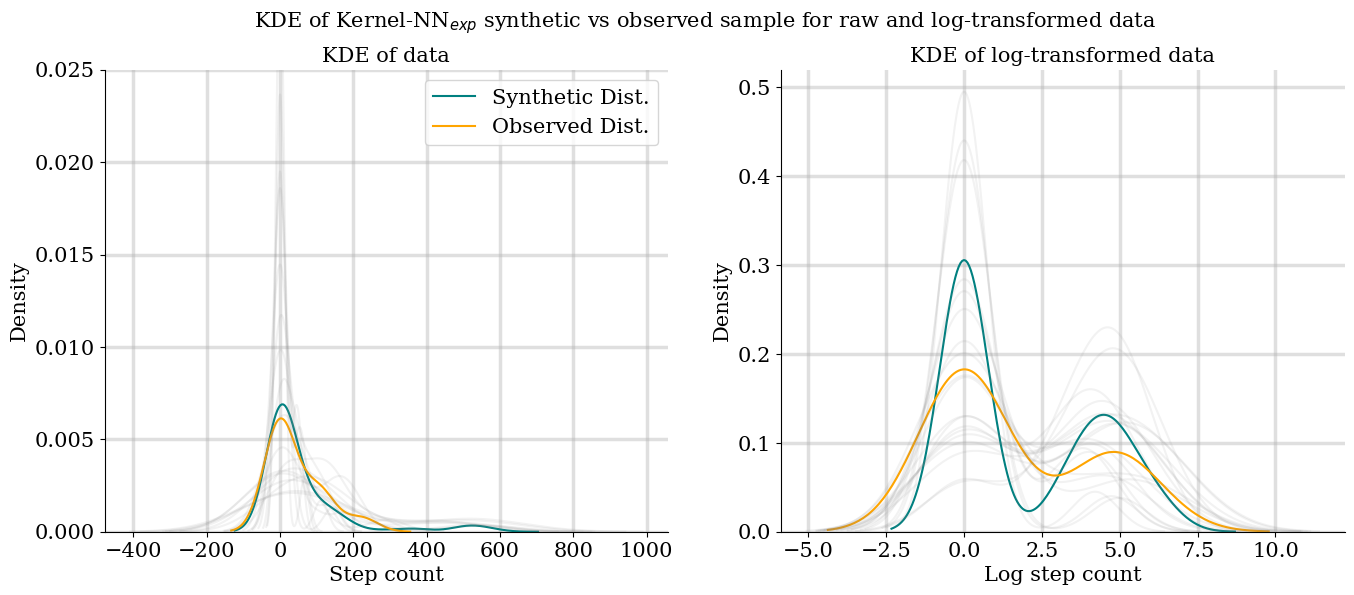

In [470]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(mmd_estimates_exp[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax1)
sns.kdeplot(M_hs[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax1)

for j in mmd_exp_neighbors[mmd_exp_unit][mmd_exp_time][0]:
  sns.kdeplot(M_hs[mmd_exp_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.1)

ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

ax1.set_ylim(0, 0.025)

sns.kdeplot(mmd_estimates_exp_log[mmd_exp_unit][mmd_exp_time].flatten(),color = "teal", ax = ax2)
sns.kdeplot(M_hs_log[mmd_exp_unit, mmd_exp_time].flatten(), color="orange", ax = ax2)

for j in mmd_exp_neighbors_log[mmd_exp_unit][mmd_exp_time][0]:
  sns.kdeplot(M_hs_log[mmd_exp_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.1)

ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Kernel-NN$_{exp}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_mmd_exp_unit7time62.pdf", bbox_inches = "tight")

In [464]:
mmd_sq_unit = 7#np.nonzero(nn_mmd_sq > 20)[0][0]
mmd_sq_time = 62 #np.nonzero(nn_mmd_sq > 20)[1][0]
mmd_sq_neighbors[0,1]
# 0, 72

(array([  4,  11,  12,  38,  56,  60,  78,  87, 107, 116, 129, 147, 154]),)

C:\Users\Caleb\AppData\Local\Temp\ipykernel_7316\1702165506.py:11: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.15)
C:\Users\Caleb\AppData\Local\Temp\ipykernel_7316\1702165506.py:17: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.15)


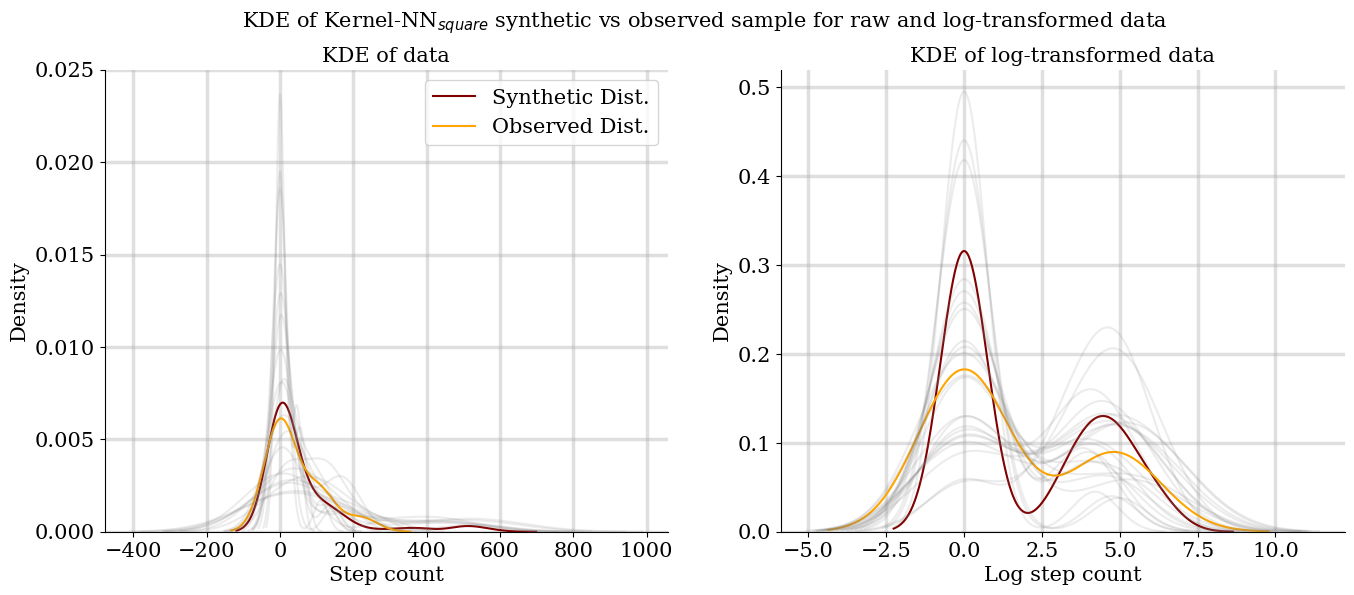

In [471]:
fig, (ax1, ax2) = plt.subplots(figsize = (16, 6), ncols = 2)

sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax1)
sns.kdeplot(M_hs[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax1)
ax1.legend(["Synthetic Dist."] + ["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
  sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.15)

sns.kdeplot(mmd_estimates_sq_log[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax2)
sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax2)

for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
  sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.15)

ax2.set_xlabel("Log step count")
ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

ax1.set_ylim(0, 0.025)

ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Kernel-NN$_{square}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
plt.savefig("kde_mmd_sq_unit7time62.pdf", bbox_inches = "tight")

In [607]:
mean_overall

array([31.69917703, 34.75433374, 37.75345824, 38.2812117 , 39.66188058,
       41.01996148, 40.85256523, 41.44843285, 40.54841534, 41.27613378,
       42.39625285, 41.83890737])

Text(0.5, 0.98, 'KDE of Kernel-NN$_{square}$ synthetic vs observed sample for raw and log-transformed data')

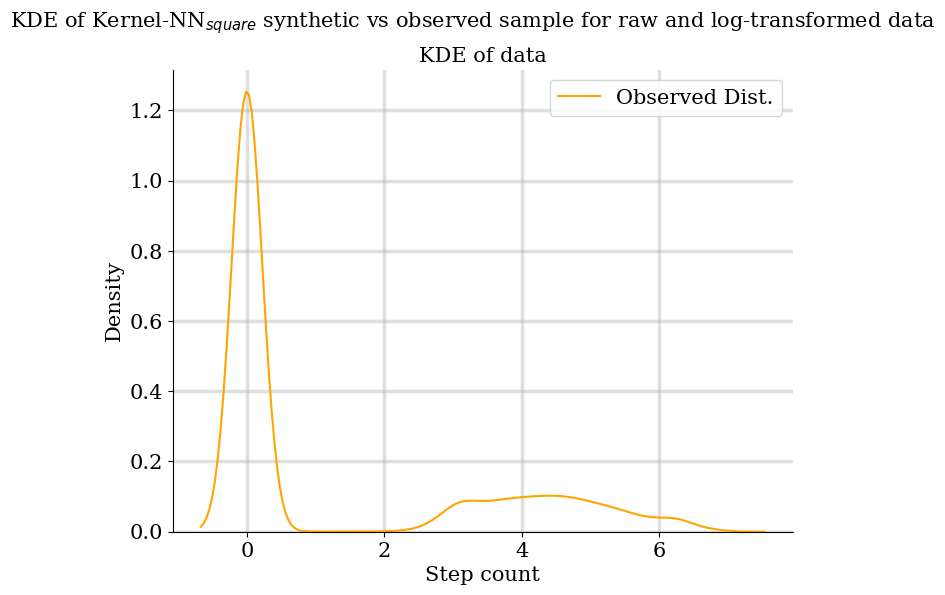

In [609]:
fig, ax1 = plt.subplots(figsize = (8, 6), ncols = 1)
M_hs_filtered = M_hs[A_hs != 2]
all_entries =  np.log(M_hs_filtered.flatten() + 1)
#sns.kdeplot(mmd_estimates_sq[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax1)
sns.kdeplot(all_entries, color="orange", ax = ax1)
ax1.legend(["Observed Dist."])
ax1.set_xlabel("Step count")
ax1.set_ylabel("Density")
ax1.set_title("KDE of data")

# for j in mmd_sq_neighbors[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs[mmd_sq_unit, j].flatten(), color = "grey", ax = ax1, alpha= 0.15)

# sns.kdeplot(mmd_estimates_sq_log[mmd_sq_unit][mmd_sq_time].flatten(),color = "maroon", ax = ax2)
# sns.kdeplot(M_hs_log[mmd_sq_unit, mmd_sq_time].flatten(), color="orange", ax = ax2)

# for j in mmd_sq_neighbors_log[mmd_sq_unit][mmd_sq_time][0]:
#   sns.kdeplot(M_hs_log[mmd_sq_unit, j].flatten(), color = "grey", ax = ax2, alpha= 0.15)

# ax2.set_xlabel("Log step count")
# ax2.set_title("KDE of log-transformed data")

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.grid(True, alpha=0.4)

#ax1.set_ylim(0, 0.025)

# ax2.spines['top'].set_visible(False)
# ax2.spines['right'].set_visible(False)
# ax2.grid(True, alpha=0.4)


fig.suptitle("KDE of Kernel-NN$_{square}$ synthetic vs observed sample for raw and log-transformed data")
#ks_error_ws2_estimates[ws2_i, ws2_j]
#plt.savefig("kde_mmd_sq_unit7time62.pdf", bbox_inches = "tight")

In [533]:
all_trials = np.load('../data_checkpoints/trials_v13_log.npy', allow_pickle=True)

(0.0, 50.0)

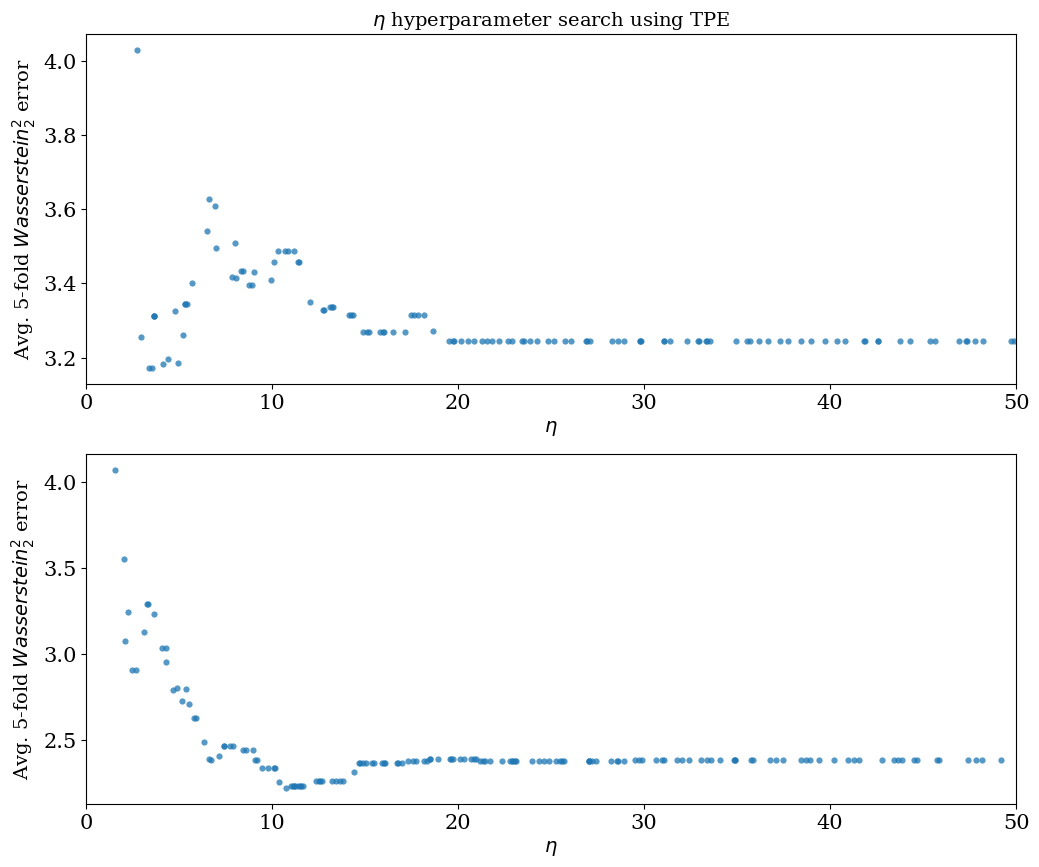

In [603]:
unit = 4
trial_ws2_front = all_trials[unit, 0]
trial_ws2_back = all_trials[unit, 1]

f, (ax1, ax2) = plt.subplots(2, figsize = (12, 10))
xs = [t['misc']['vals']['eta'] for t in trial_ws2_front.trials]
ys = [t['result']['loss'] for t in trial_ws2_front.trials]
xs_back = [t['misc']['vals']['eta'] for t in trial_ws2_back.trials]
ys_back = [t['result']['loss'] for t in trial_ws2_back.trials]

ax1.scatter(xs, ys, s=20, linewidth=0.01, alpha=0.75)
ax1.set_title('$\eta$ hyperparameter search using TPE', fontsize=14)
ax1.set_xlabel('$\eta$', fontsize=14)
ax1.set_ylabel('Avg. 5-fold $Wasserstein_2^2$ error', fontsize=14)

ax1.set_xlim((0, 50))

ax2.scatter(xs_back, ys_back, s=20, linewidth=0.01, alpha=0.75)
#ax2.set_title('$\eta$ hyperparameter search using TPE', fontsize=14)
ax2.set_xlabel('$\eta$', fontsize=14)
ax2.set_ylabel('Avg. 5-fold $Wasserstein_2^2$ error', fontsize=14)
ax2.set_xlim((0, 50))

<Axes: ylabel='Density'>

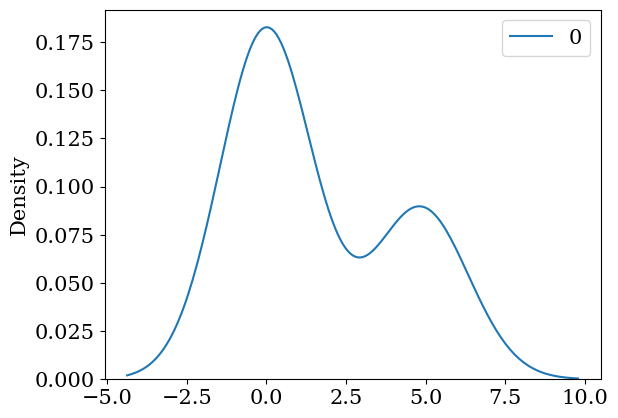

In [593]:
sns.kdeplot(M_hs_log[7, 62])

In [598]:
t_x, t_y = np.nonzero(A_hs == 1)
for i in range(100, 140):
  print(M_hs_log[t_x[i], t_y[i]])
  print("\n")

[[4.75359019]
 [5.15329159]
 [0.        ]
 [0.        ]
 [0.        ]
 [4.49980967]
 [3.52636052]
 [3.04452244]
 [4.29045944]
 [4.66343909]
 [5.12396398]
 [4.82831374]]


[[0.        ]
 [4.00733319]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [5.45103845]
 [6.16541785]
 [3.71357207]
 [2.94443898]
 [0.        ]]


[[4.24849524]
 [5.55295958]
 [3.13549422]
 [3.40119738]
 [0.        ]
 [0.        ]
 [3.52636052]
 [4.79579055]
 [4.09434456]
 [0.        ]
 [3.13549422]
 [0.        ]]


[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [5.9348942 ]
 [6.23636959]
 [5.33753808]
 [0.        ]
 [6.01126717]
 [5.74939299]]


[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [5.19849703]
 [4.79579055]
 [0.        ]]


[[0.        ]
 [3.25809654]
 [3.04452244]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0. 

## Computing fit with log transform vs not

In [610]:
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

M_hs_log =  np.log(M_hs + 1)


In [612]:
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v13_log.npy")
mmd_exp_estimates_log = np.load("../data_checkpoints/mmd_exp_estimates_v13_log.npy", allow_pickle = True)
mmd_sq_estimates_log = np.load("../data_checkpoints/mmd_sq_estimates_v13_log.npy", allow_pickle = True)

ws2_estimates_reg = np.load("ws2_estimates_v14.npy")
mmd_exp_estimates_reg = np.load("mmd_exp_estimates_v14.npy", allow_pickle = True)
mmd_sq_estimates_reg = np.load("mmd_sq_estimates_v14.npy", allow_pickle = True)


In [613]:
from scipy.stats import kstest

In [618]:
ks_error_ws2_estimates_reg = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    ks_error_ws2_estimates_reg[i, j] = kstest(ws2_estimates_reg[i, j], 
                                          M_hs[i, j].squeeze()).statistic
    
ks_error_ws2_estimates_log = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    ks_error_ws2_estimates_log[i, j] = kstest(ws2_estimates_log[i, j], 
                                          M_hs_log[i, j].squeeze()).statistic


In [619]:
ks_mmd_error_exp_reg= np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_exp_estimates_reg[i][j]
    truth = M_hs[i, j].squeeze()
    if est is None:
      ks_mmd_error_exp_reg[i, j] = np.nan
    else:
      ks_mmd_error_exp_reg[i, j] = kstest(est.squeeze(), truth).statistic

ks_mmd_error_exp_log= np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_exp_estimates_log[i][j]
    truth = M_hs_log[i, j].squeeze()
    if est is None:
      ks_mmd_error_exp_log[i, j] = np.nan
    else:
      ks_mmd_error_exp_log[i, j] = kstest(est.squeeze(), truth).statistic


In [620]:
ks_mmd_error_sq_reg = np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_sq_estimates_reg[i][j]
    truth = M_hs[i, j].squeeze()
    if est is None:
      ks_mmd_error_sq_reg[i, j] = np.nan
    else:
      ks_mmd_error_sq_reg[i, j] = kstest(est.squeeze(), truth).statistic

ks_mmd_error_sq_log= np.full([N, T], np.nan)
for i in range(N):
  for j in range(T):
    est = mmd_sq_estimates_log[i][j]
    truth = M_hs_log[i, j].squeeze()
    if est is None:
      ks_mmd_error_sq_log[i, j] = np.nan
    else:
      ks_mmd_error_sq_log[i, j] = kstest(est.squeeze(), truth).statistic


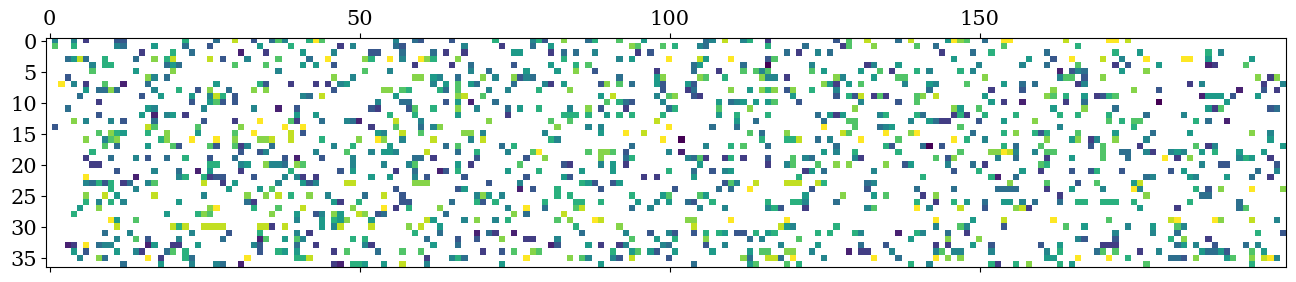

In [622]:
matshow(ks_error_ws2_estimates_reg, aspect = "auto")

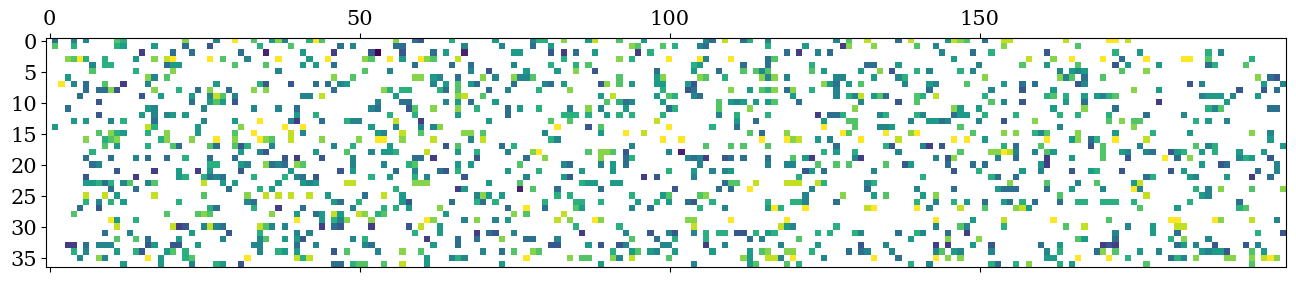

In [623]:
matshow(ks_error_ws2_estimates_log, aspect = "auto")

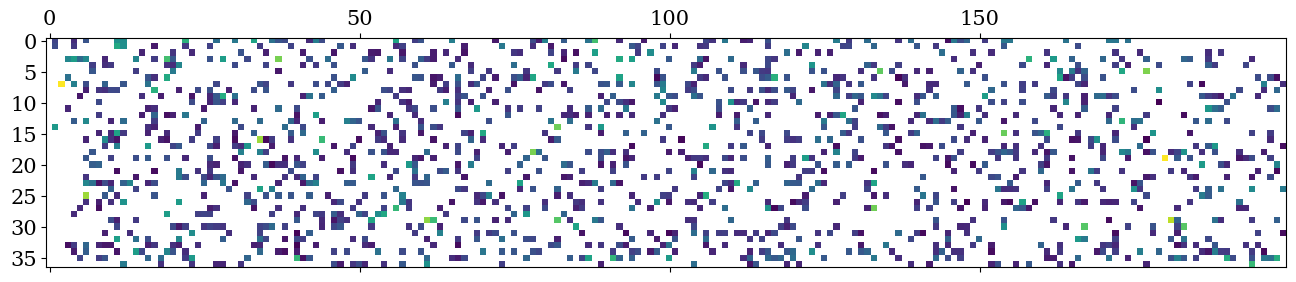

In [629]:
matshow(ks_mmd_error_sq_reg, aspect = "auto")

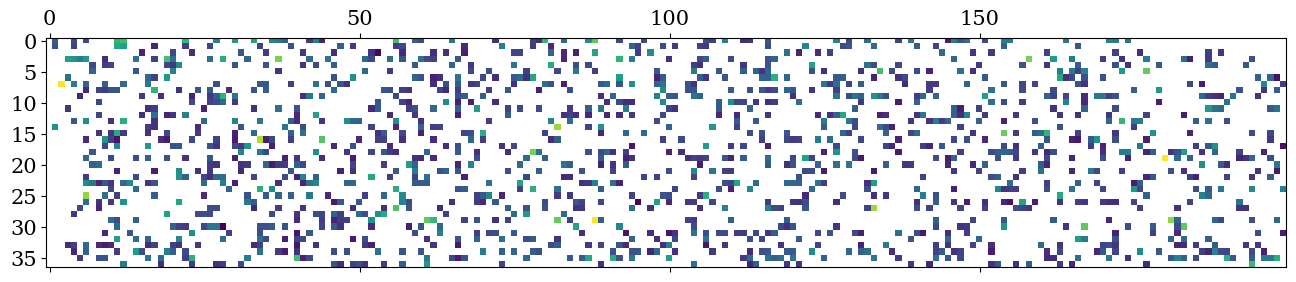

In [628]:
matshow(ks_mmd_error_sq_log, aspect = "auto")

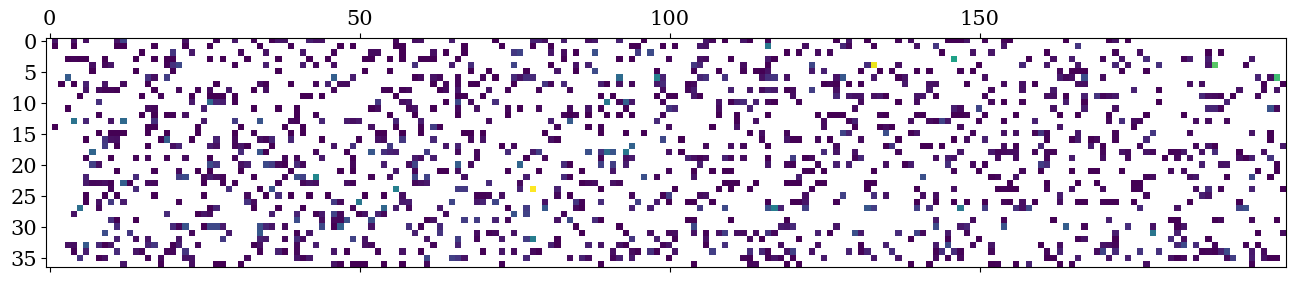

In [627]:
matshow(abs(ks_mmd_error_exp_log - ks_mmd_error_exp_reg), aspect = "auto")

### Visualizing Bias-Variance tradeoff

I will do one for log transform, one for raw data

In [8]:
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

M_hs_log =  np.log(M_hs + 1)

M_hs_log = np.sort(M_hs_log, axis = 2)


In [9]:
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v19_log.npy")
mmd_exp_estimates_log = np.load("../data_checkpoints/mmd_exp_estimates_v19_log.npy", allow_pickle = True)
mmd_sq_estimates_log = np.load("../data_checkpoints/mmd_sq_estimates_v19_log.npy", allow_pickle = True)

ws2_nn_log = np.load("../data_checkpoints/ws2_nncount_v19_log.npy")
mmd_exp_nn_log = np.load("../data_checkpoints/mmd_exp_nncount_v19_log.npy")
mmd_sq_nn_log = np.load("../data_checkpoints/mmd_sq_nncount_v19_log.npy")

# ws2_estimates_reg = np.load("../data_checkpoints/ws2_estimates_v19.npy")
# mmd_exp_estimates_reg = np.load("../data_checkpoints/mmd_exp_estimates_v19.npy", allow_pickle = True)
# mmd_sq_estimates_reg = np.load("../data_checkpoints/mmd_sq_estimates_v19.npy", allow_pickle = True)

In [10]:
eta_stars_log = np.load("../data_checkpoints/eta_stars_v19_log.npy")
eta_stars_log_old = np.load("../data_checkpoints/eta_stars_v18_log.npy")

In [11]:
ws2_eta_stars_log = eta_stars_log[:, :2]
mmd_exp_eta_stars_log = eta_stars_log[:, 2:4]
mmd_sq_eta_stars_log = eta_stars_log[:, 4:6]

In [126]:
# each data frame should have 1485 entries

In [12]:
trd_list = []

for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      error = dnn.wasserstein2_dist(M_hs_log[i, j], ws2_estimates_log[i,j])
      nn = ws2_nn_log[i, j]
      # if j is in the first half, use back half eta, otherwise use front half eta.
      eta = ws2_eta_stars_log[i, 1] if j < (T // 2) else ws2_eta_stars_log[i, 0]
      trd_list.append([error, nn, eta])

df_tradeoff_ws2 = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:239: RuntimeWarning: Mean of empty slice
  return np.nanmean((Y_i - Y_j)**2)


In [137]:
df_tradeoff_ws2

,error,neighbors,eta_star
0,10.288807,8.0,6.625489
1,7.296511,28.0,6.625489
2,9.016880,33.0,6.625489
3,8.867146,21.0,6.625489
4,6.325844,19.0,6.625489
...,...,...,...
1480,4.023949,12.0,39.364890
1481,4.359938,22.0,39.364890
1482,5.362638,26.0,39.364890
1483,4.475962,24.0,39.364890


In [13]:
trd_list = []

for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      error = dnn.sqmmd_est2(M_hs_log[i, j], mmd_exp_estimates_log[i][j], kernel = "exponential")
      nn = mmd_exp_nn_log[i, j]
      # if j is in the first half, use back half eta, otherwise use front half eta.
      eta = mmd_exp_eta_stars_log[i, 1] if j < (T // 2) else mmd_exp_eta_stars_log[i, 0]
      trd_list.append([error, nn, eta])

df_tradeoff_mmd_exp = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:45: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2)) # m by n matrix with x_i^Ty_j
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:58: RuntimeWarning: invalid value encountered in subtract
  kYY = np.exp( -0.5*( dYY_nn + np.transpose(dYY_nn) - 2*YY ))


In [14]:
trd_list = []

for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      error = dnn.sqmmd_est2(M_hs_log[i, j], mmd_sq_estimates_log[i][j], kernel = "square")
      nn = mmd_sq_nn_log[i, j]
      # if j is in the first half, use back half eta, otherwise use front half eta.
      eta = mmd_sq_eta_stars_log[i, 1] if j < (T // 2) else mmd_sq_eta_stars_log[i, 0]
      trd_list.append([error, nn, eta])

df_tradeoff_mmd_sq = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])

TypeError: 'NoneType' object is not subscriptable

In [143]:
df_tradeoff_mmd_sq

,error,neighbors,eta_star
0,16.717164,5.0,0.008489
1,0.000000,9.0,0.008489
2,7.894740,7.0,0.008489
3,136.588781,6.0,0.008489
4,104.343506,8.0,0.008489
...,...,...,...
1480,27.169686,12.0,1214.023328
1481,3.102380,22.0,1214.023328
1482,0.000000,26.0,1214.023328
1483,0.654872,24.0,1214.023328


<Axes: xlabel='eta_star', ylabel='error'>

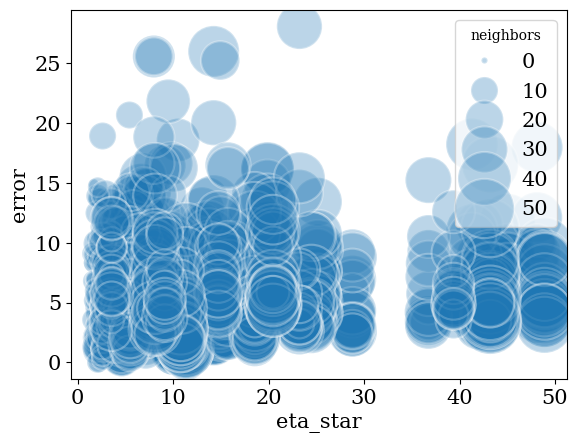

In [145]:
sns.scatterplot(data = df_tradeoff_ws2, x = "eta_star", y = "error", size = "neighbors", alpha = 0.3, sizes = (20, 2000))

In [15]:
eta_trials_log = np.load("../data_checkpoints/trials_v18_log.npy", allow_pickle=True)

eta_trials_log.shape



(37, 6)

Text(0, 0.5, 'Avg. 5-fold $Wasserstein_2^2$ error')

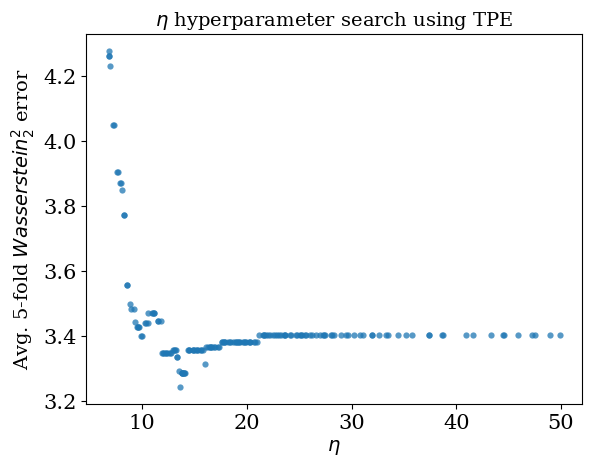

In [153]:
f, ax = plt.subplots(1)
xs = [t['misc']['vals']['eta'] for t in eta_trials_log[1, 0].trials]
ys = [t['result']['loss'] for t in eta_trials_log[1, 0].trials]
ax.scatter(xs, ys, s=20, linewidth=0.01, alpha=0.75)
ax.set_title('$\eta$ hyperparameter search using TPE', fontsize=14)
ax.set_xlabel('$\eta$', fontsize=14)
ax.set_ylabel('Avg. 5-fold $Wasserstein_2^2$ error', fontsize=14)

In [355]:
print(np.nonzero(A_hs[30] == 1))

(array([ 11,  20,  21,  22,  25,  26,  27,  28,  34,  35,  36,  38,  44,
        46,  47,  52,  58,  60,  63,  85,  92, 104, 118, 119, 120, 127,
       143, 147, 148, 154, 164, 167, 174, 178, 182, 183]),)


In [17]:
# tune eta for some select entries -> use the values of eta generated in the eta search as the x axis,
# estimate the error for that entry using each of the etas and retrieve the size of the neighborhoods.
unit = 30
time = 154

cv_mhs = M_hs_log.copy()
cv_ahs = A_hs.copy()

cv_mhs = np.delete(cv_mhs, time, axis = 1)
cv_ahs = np.delete(cv_ahs, time, axis = 1)

trd_list = []
# sample split?

# cv_col_diffs = dnn.get_col_differences(cv_mhs, cv_ahs, metric = "wasserstein2", kernel = None)

# eta_star, trials = cv_dnn.search_eta(cv_mhs, cv_ahs, k = 5, row = unit,
#                                      col_dists=cv_col_diffs, est_func=dnn.estimate_row, 
#                                      metric = "wasserstein2", range_min = 0, range_max = 50)
#print(eta_star)
dist_A = A_hs.copy()
dist_A[unit] = 0
full_col_diffs = dnn.get_col_differences(M_hs_log, dist_A, metric = "wasserstein2", kernel = None)

# ests, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
#                                              cols = full_col_diffs, eta = eta_star, 
#                                              metric = "wasserstein2", ret_nn = True)

#for t in trials:
  #eta_val = t['misc']['vals']['eta']
vals = np.arange(0.5, 20, 1)

for eta_val in vals:
  est, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
                                              col_dists = full_col_diffs, eta = eta_val, 
                                              metric = "wasserstein2", ret_nn = True)
  error = dnn.wasserstein2_dist(M_hs_log[unit, time], est[time])
  trd_list.append([error, nn_count[time], eta_val])


df_tradeoff_ws2 = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])
  



c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:273: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean((Z_cp.swapaxes(0, 1)[:, None, :,  :] - Z_cp.swapaxes(0, 1))**2, axis = -1)
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:276: RuntimeWarning: Mean of empty slice
  diffs = np.nanmean(diffs, axis = -1)


In [327]:
print(vals)

[ 0.5  1.5  2.5  3.5  4.5  5.5  6.5  7.5  8.5  9.5 10.5 11.5 12.5 13.5
 14.5 15.5 16.5 17.5 18.5 19.5]


In [286]:
est, _, _ = dnn.estimate_row(M_hs_log, A_hs, 0, cols = [27],
                                              col_dists = full_col_diffs, eta = 7.925575259057329, 
                                              metric = "wasserstein2", ret_nn = True)
dnn.wasserstein2_dist(est[time], M_hs_log[unit, time])

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:239: RuntimeWarning: Mean of empty slice
  return np.nanmean((Y_i - Y_j)**2)


np.float64(nan)

In [314]:
print(eta_stars_log[0, 1])
print(eta_stars_log_old[0, 1])

18.345012710118148
6.62548919956238


In [281]:
print(ws2_estimates_log[unit, time])
print(est[time])

[0.08401784 0.36505299 0.6097149  0.69568896 0.88684558 1.32804476
 1.76121479 2.21820424 2.61059768 3.09318924 3.77528874 4.32730264]
[0.08401784 0.36505299 0.6097149  0.69568896 0.88684558 1.32804476
 1.76121479 2.21820424 2.61059768 3.09318924 3.77528874 4.32730264]


In [313]:
dnn.wasserstein2_dist(M_hs_log[unit, time], ws2_estimates_log[unit, time])

np.float64(6.952479121129258)

In [192]:
df_filtered_ws2 = df_tradeoff_ws2[df_tradeoff_ws2["eta_star"] < 20]

In [ ]:
# 1, 4 is a decent possibility

In [345]:
df_tradeoff_ws2

,error,neighbors,eta_star
0,5.797138,8.0,0.5
1,5.815893,14.0,1.5
2,5.791411,16.0,2.5
3,5.816379,20.0,3.5
4,5.982138,22.0,4.5
5,6.014980,25.0,5.5
6,5.916733,26.0,6.5
7,5.802730,30.0,7.5
8,5.802730,30.0,8.5
9,5.883339,31.0,9.5


Text(0, 0.5, '$Wasserstein^2_2$ error')

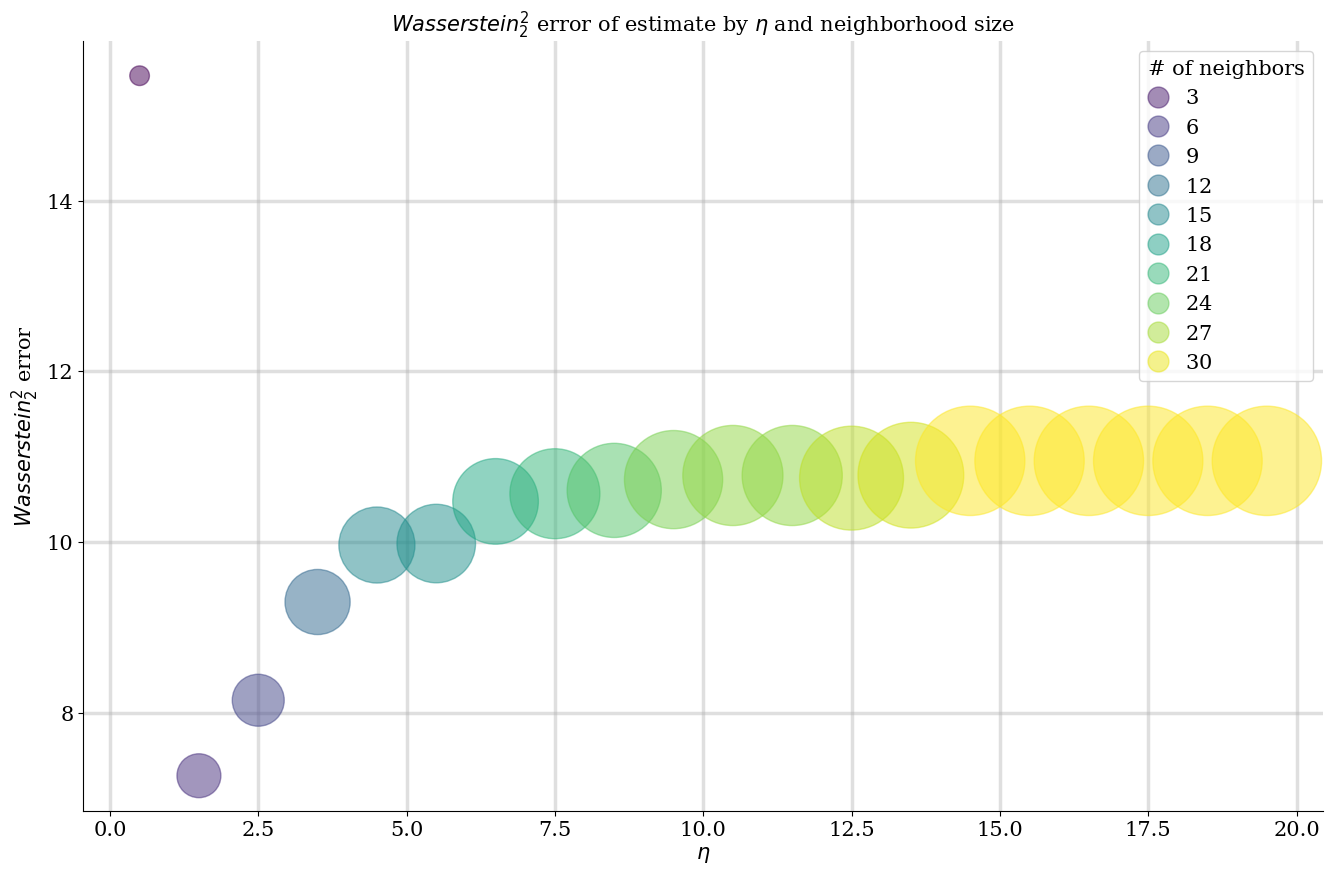

In [18]:
fig, ax = plt.subplots(figsize = (16, 10))
scatter = ax.scatter(x = df_tradeoff_ws2["eta_star"], y = df_tradeoff_ws2["error"], s = df_tradeoff_ws2["neighbors"] * 200, alpha = 0.5, c = df_tradeoff_ws2["neighbors"], cmap = "viridis")
#hand, labels = scatter.legend_elements(prop = "sizes", alpha = 0.6)
ax.legend(*scatter.legend_elements(), title = "# of neighbors", title_fontsize = 15, handlelength = 1, alignment = "left")
#ax.legend(hand, labels)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)

ax.set_title("$Wasserstein^2_2$ error of estimate by $\eta$ and neighborhood size")
ax.set_xlabel("$\eta$")
ax.set_ylabel("$Wasserstein^2_2$ error")

#plt.savefig("ws2_error_eta_size.pdf", bbox_inches = "tight")

In [454]:
print(np.nonzero(A_hs[30] == 1))

(array([ 11,  20,  21,  22,  25,  26,  27,  28,  34,  35,  36,  38,  44,
        46,  47,  52,  58,  60,  63,  85,  92, 104, 118, 119, 120, 127,
       143, 147, 148, 154, 164, 167, 174, 178, 182, 183]),)


In [20]:
# tune eta for some select entries -> use the values of eta generated in the eta search as the x axis,
# estimate the error for that entry using each of the etas and retrieve the size of the neighborhoods.
unit = 30
time = 154

cv_mhs = M_hs_log.copy()
cv_ahs = A_hs.copy()

cv_mhs = np.delete(cv_mhs, time, axis = 1)
cv_ahs = np.delete(cv_ahs, time, axis = 1)

trd_list = []
# sample split?

# cv_col_diffs = dnn.get_col_differences(cv_mhs, cv_ahs, metric = "wasserstein2", kernel = None)

# eta_star, trials = cv_dnn.search_eta(cv_mhs, cv_ahs, k = 5, row = unit,
#                                      col_dists=cv_col_diffs, est_func=dnn.estimate_row, 
#                                      metric = "wasserstein2", range_min = 0, range_max = 50)
#print(eta_star)
dist_A = A_hs.copy()
dist_A[unit] = 0
full_col_diffs = dnn.get_col_differences(M_hs_log, dist_A, metric = "mmd", kernel = "exponential")

# ests, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
#                                              cols = full_col_diffs, eta = eta_star, 
#                                              metric = "wasserstein2", ret_nn = True)

#for t in trials:
  #eta_val = t['misc']['vals']['eta']
vals = np.arange(0, 1, 0.05)

for eta_val in vals:
  est, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
                                              col_dists = full_col_diffs, eta = eta_val, 
                                              metric = "mmd", ret_nn = True)
  print(est[time])
  error = dnn.sqmmd_est2(M_hs_log[unit, time], est[time], kernel = "exponential")
  trd_list.append([error, nn_count[time], eta_val])


df_tradeoff_mmd_exp = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])
  



[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [3.33220451]
 [4.47733681]
 [4.62497281]
 [4.75359019]
 [0.        ]
 [0.        ]
 [0.        ]
 [2.83321334]
 [5.45103845]
 [5.79605775]
 [6.14203741]
 [6.16751649]
 [6.22653667]
 [6.23244802]
 [6.24997524]
 [6.25575004]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [2.99573227]
 [5.42934563]
 [5.97126184]
 [6.05678401]
 [6.24610677]
 [0.        ]
 [3.40119738]
 [3.55534806]
 [4.07753744]
 [4.57471098]
 [5.16478597]
 [5.24174702]
 [5.26785816]
 [5.33271879]
 [5.76205138]
 [6.12468339]
 [6.29156914]]
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0. 

In [460]:
eta_stars_log[1, 2]

np.float64(0.33247019427491786)

In [474]:
try_list = []
for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      err = dnn.sqmmd_est2(M_hs_log[i, j], mmd_exp_estimates_log[i, j], kernel = "exponential")
      if err > 0:
        try_list.append((i, j))



c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:45: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2)) # m by n matrix with x_i^Ty_j
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:58: RuntimeWarning: invalid value encountered in subtract
  kYY = np.exp( -0.5*( dYY_nn + np.transpose(dYY_nn) - 2*YY ))


In [489]:
try_list[5]

(0, 27)

In [456]:
df_tradeoff_mmd_exp

,error,neighbors,eta_star
0,0,2.0,0.00
1,0,6.0,0.05
2,0,9.0,0.10
3,0,13.0,0.15
4,0,14.0,0.20
5,0,18.0,0.25
6,0,19.0,0.30
7,0,20.0,0.35
8,0,20.0,0.40
9,0,20.0,0.45


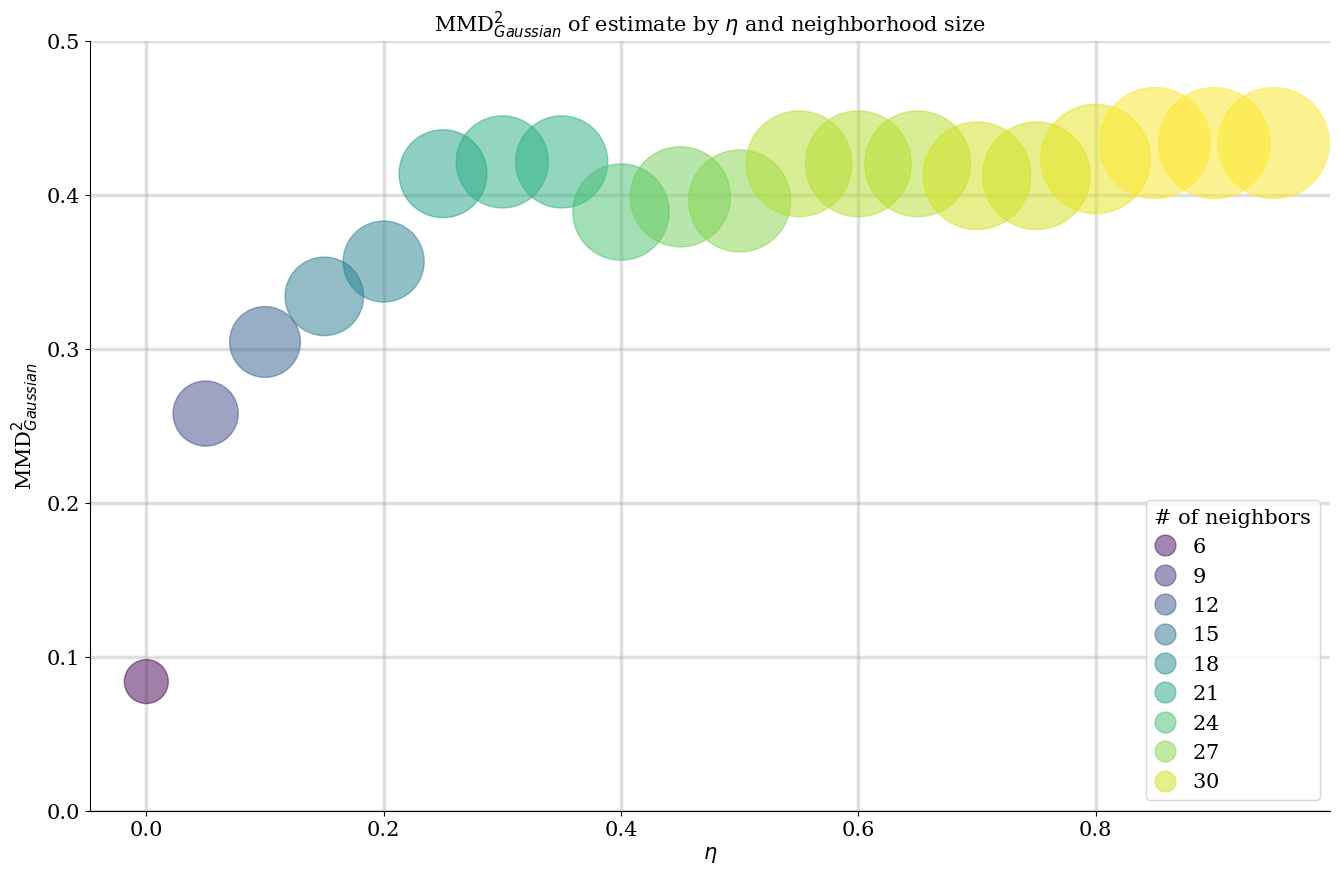

In [29]:
fig, ax = plt.subplots(figsize = (16, 10))
scatter = ax.scatter(x = df_tradeoff_mmd_exp["eta_star"], y = df_tradeoff_mmd_exp["error"], s = df_tradeoff_mmd_exp["neighbors"] * 200, alpha = 0.5, c = df_tradeoff_mmd_exp["neighbors"], cmap = "viridis")
#hand, labels = scatter.legend_elements(prop = "sizes", alpha = 0.6)
ax.legend(*scatter.legend_elements(), title = "# of neighbors", title_fontsize = 15, handlelength = 1, alignment = "left")
#ax.legend(hand, labels)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)

ax.set_ylim([0.0, 0.5])

ax.set_title("MMD$^2_{Gaussian}$ of estimate by $\eta$ and neighborhood size")
ax.set_xlabel("$\eta$")
ax.set_ylabel("MMD$^2_{Gaussian}$")

plt.savefig("mmd_exp_error_eta_size.pdf", bbox_inches = "tight")

# prev 0, 27

In [501]:
full_col_diffs

array([[         inf,          nan,          nan, ...,          nan,
                 nan,          nan],
       [         nan,          inf,          nan, ...,          nan,
                 nan,          nan],
       [         nan,          nan,          inf, ...,          nan,
                 nan,  16.89141173],
       ...,
       [         nan,          nan,          nan, ...,          inf,
        215.73689586,          nan],
       [         nan,          nan,          nan, ..., 215.73689586,
                 inf,          nan],
       [         nan,          nan,  16.89141173, ...,          nan,
                 nan,          inf]])

In [516]:
try_list = []
for i in range(N):
  for j in range(T):
    if A_hs[i, j] == 1:
      err = dnn.sqmmd_est2(M_hs_log[i, j], mmd_exp_estimates_log[i, j], kernel = "square")
      if err > 0:
        try_list.append((i, j))

c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:45: RuntimeWarning: invalid value encountered in matmul
  XY = np.matmul(dat1, np.transpose(dat2)) # m by n matrix with x_i^Ty_j
c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:62: RuntimeWarning: invalid value encountered in scalar subtract
  val = (np.sum(kXX) - np.sum(np.diag(kXX)))/(m*(m - 1)) + (np.sum(kYY) - np.sum(np.diag(kYY)))/(n*(n - 1)) - 2*np.sum(kXY)/(n*m)


In [530]:
try_list[100]

(3, 55)

In [23]:
# tune eta for some select entries -> use the values of eta generated in the eta search as the x axis,
# estimate the error for that entry using each of the etas and retrieve the size of the neighborhoods.
unit = 30
time = 154

cv_mhs = M_hs_log.copy()
cv_ahs = A_hs.copy()

cv_mhs = np.delete(cv_mhs, time, axis = 1)
cv_ahs = np.delete(cv_ahs, time, axis = 1)

trd_list = []
# sample split?

# cv_col_diffs = dnn.get_col_differences(cv_mhs, cv_ahs, metric = "wasserstein2", kernel = None)

# eta_star, trials = cv_dnn.search_eta(cv_mhs, cv_ahs, k = 5, row = unit,
#                                      col_dists=cv_col_diffs, est_func=dnn.estimate_row, 
#                                      metric = "wasserstein2", range_min = 0, range_max = 50)
#print(eta_star)
dist_A = A_hs.copy()
dist_A[unit] = 0
full_col_diffs = dnn.get_col_differences(M_hs_log, dist_A, metric = "mmd", kernel = "square")

# ests, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
#                                              cols = full_col_diffs, eta = eta_star, 
#                                              metric = "wasserstein2", ret_nn = True)

#for t in trials:
  #eta_val = t['misc']['vals']['eta']
vals = np.arange(0, 300, 15)

for eta_val in vals:
  est, nn_count, neighbors = dnn.estimate_row(M_hs_log, A_hs, unit, cols = [time],
                                              col_dists = full_col_diffs, eta = eta_val, 
                                              metric = "mmd", ret_nn = True)
  error = dnn.sqmmd_est2(M_hs_log[unit, time], est[time], kernel = "square")
  trd_list.append([error, nn_count[time].astype(int), eta_val])


df_tradeoff_mmd_sq = pd.DataFrame(trd_list, columns = ["error", "neighbors", "eta_star"])
  
# prev: 3, 55


c:\Users\Caleb\HeartstepsDNN\Heartsteps-DNN\src\dnn.py:109: RuntimeWarning: Mean of empty slice
  val = np.nanmean(val_all)


In [520]:
df_tradeoff_mmd_sq

,error,neighbors,eta_star
0,330.739264,4.0,0
1,335.223211,6.0,15
2,294.739002,8.0,30
3,319.857291,11.0,45
4,341.998143,13.0,60
5,341.998143,13.0,75
6,332.181751,14.0,90
7,316.528950,17.0,105
8,316.528950,17.0,120
9,316.528950,17.0,135


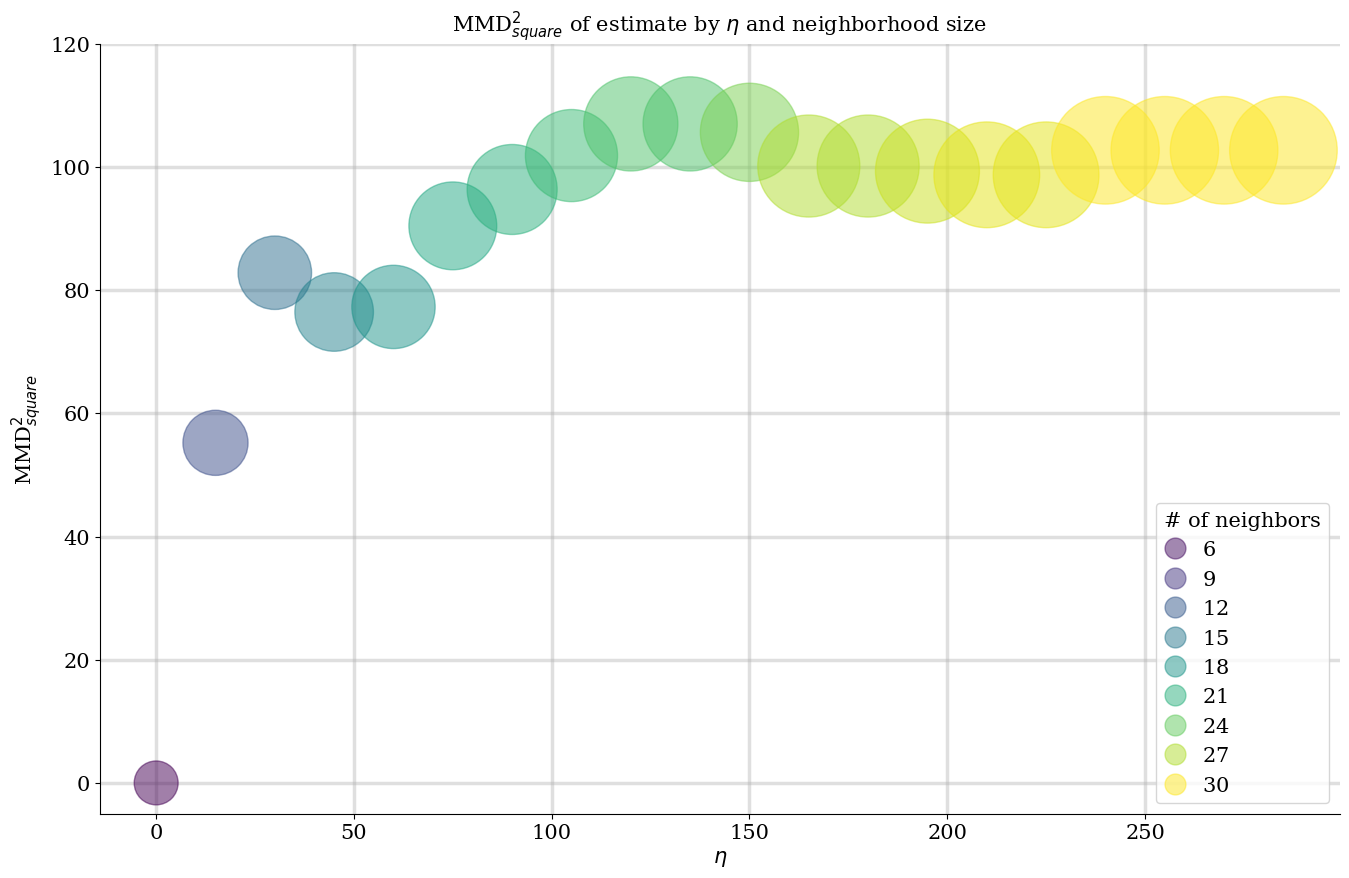

In [28]:
fig, ax = plt.subplots(figsize = (16, 10))
scatter = ax.scatter(x = df_tradeoff_mmd_sq["eta_star"], y = df_tradeoff_mmd_sq["error"], s = df_tradeoff_mmd_sq["neighbors"] * 200, alpha = 0.5, c = df_tradeoff_mmd_sq["neighbors"], cmap = "viridis")
#hand, labels = scatter.legend_elements(prop = "sizes", alpha = 0.6)
ax.legend(*scatter.legend_elements(), title = "# of neighbors", title_fontsize = 15, handlelength = 1, alignment = "left")
#ax.legend(hand, labels)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)

ax.set_ylim([-5, 120])

ax.set_title("MMD$^2_{square}$ of estimate by $\eta$ and neighborhood size")
ax.set_xlabel("$\eta$")
ax.set_ylabel("MMD$^2_{square}$")

plt.savefig("mmd_sq_error_eta_size.pdf", bbox_inches = "tight")

# prev: 3, 5

In [444]:
dnn.sqmmd_est2(M_hs_log[0, 4].reshape((12, 1)), M_hs_log[0, 4].reshape((12, 1)), kernel = "exponential")

np.float64(-0.10406480803283558)

In [469]:
dnn.sqmmd_est2(np.array([[1], [0], [4], [5], [5]]), np.array([[2], [0], [4], [5], [1]]), kernel = "exponential")

np.float64(-0.2219913195738037)

<Axes: ylabel='Density'>

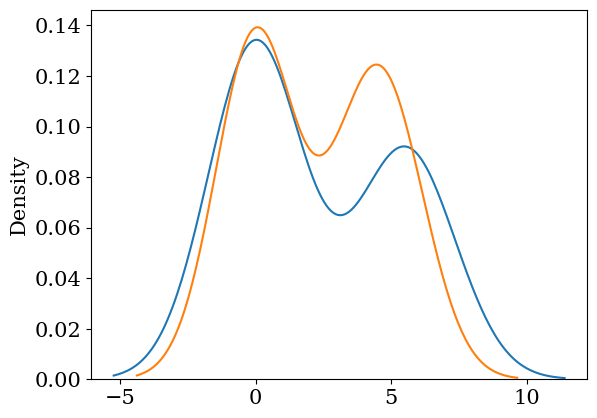

In [443]:
sns.kdeplot(M_hs_log[0, 1].flatten())
sns.kdeplot(M_hs_log[0, 4].flatten())

In [ ]:
M_hs = np.load("../data_checkpoints/heartsteps_data.npy")
A_hs = np.load("../data_checkpoints/heartsteps_mask.npy")

M_hs = M_hs[:, :, :, None]

# truncate the data as most users have had 40 days
M_hs = M_hs[:, 0:200]
A_hs = A_hs[:, 0:200]

N, T, n, d = M_hs.shape

M_hs_log =  np.log(M_hs + 1)


In [ ]:
ws2_estimates_log = np.load("../data_checkpoints/ws2_estimates_v13_log.npy")
mmd_exp_estimates_log = np.load("../data_checkpoints/mmd_exp_estimates_v13_log.npy", allow_pickle = True)
mmd_sq_estimates_log = np.load("../data_checkpoints/mmd_sq_estimates_v13_log.npy", allow_pickle = True)

ws2_estimates_reg = np.load("ws2_estimates_v14.npy")
mmd_exp_estimates_reg = np.load("mmd_exp_estimates_v14.npy", allow_pickle = True)
mmd_sq_estimates_reg = np.load("mmd_sq_estimates_v14.npy", allow_pickle = True)


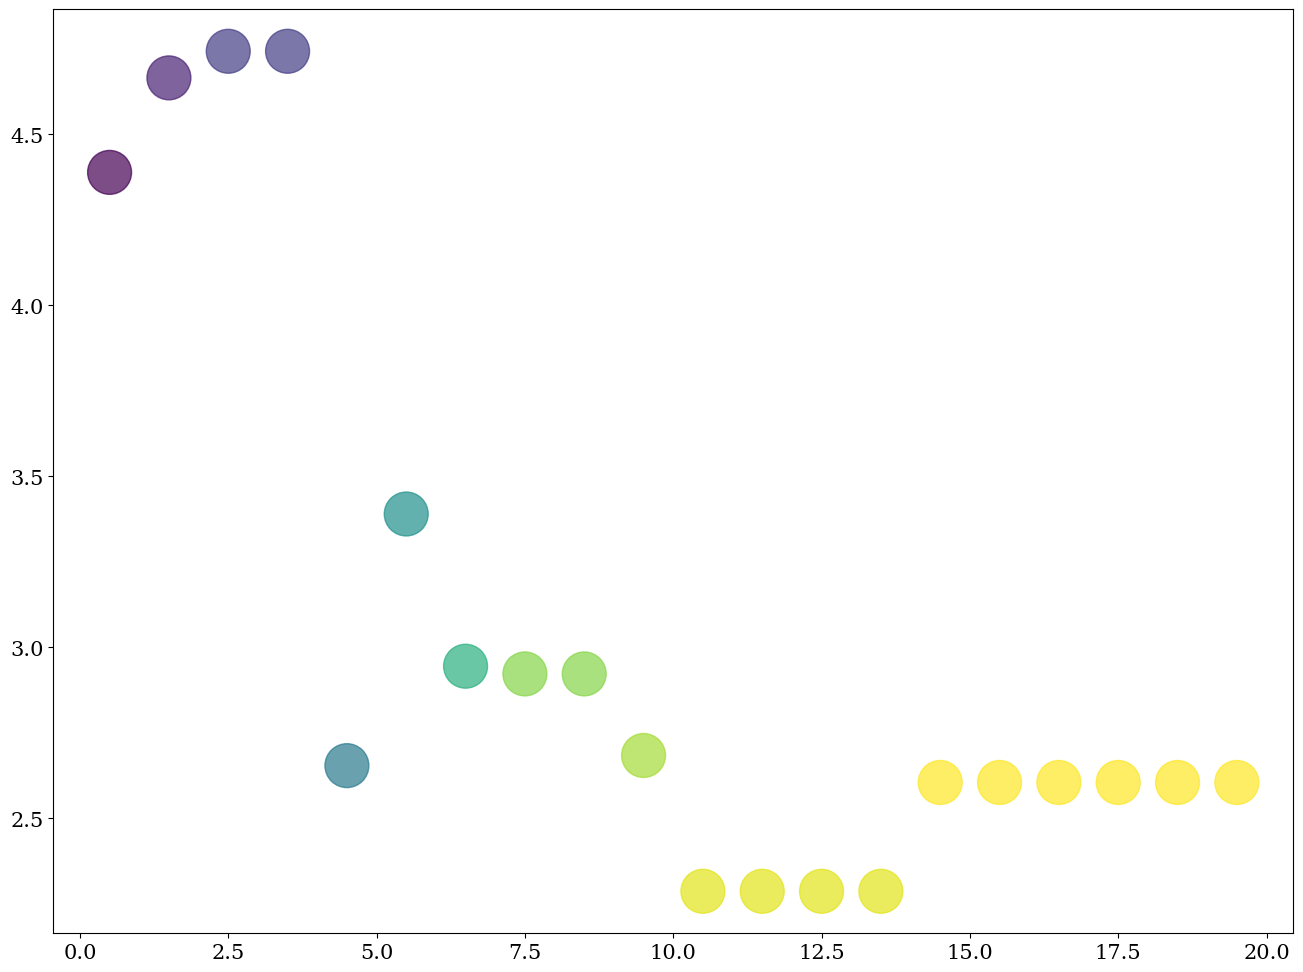

In [363]:
fig, ax = plt.subplots(figsize = (16, 12))
ax.scatter(x = df_tradeoff_ws2["eta_star"], y = df_tradeoff_ws2["error"], alpha = 0.7, s = 1000, c = df_tradeoff_ws2["neighbors"], cmap = "viridis")

<Axes: ylabel='Density'>

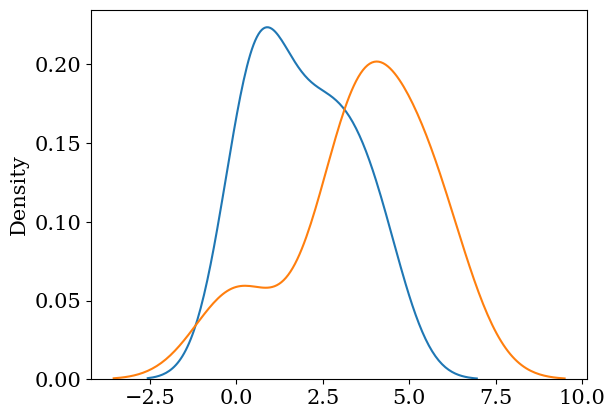

In [351]:
sns.kdeplot(ws2_estimates_log[0, 127].flatten())
sns.kdeplot(M_hs_log[0, 127].flatten())

In [2]:
import numpy as np

In [8]:
mcar_sims = np.load("trial_0.npy", allow_pickle=True)


In [10]:
mcar_sims = mcar_sims.astype(float)

In [11]:
mcar_sims.shape

(4, 30)

In [81]:
mcar_sims = np.load("trial_0_mcar_v2.npy", allow_pickle = True).astype(float)

In [82]:
mcar_sims

array([[0.00000000e+00, 0.00000000e+00, 8.81000148e-01,            nan,
                   nan, 6.33411316e-02,            nan, 1.41114162e-01,
        2.75007858e-01, 3.48223876e-01, 3.32498036e+00,            nan,
                   nan, 0.00000000e+00, 5.35822343e-01,            nan,
                   nan,            nan,            nan,            nan,
        2.78301027e+00, 2.05872095e+01, 5.57371254e-01,            nan,
        1.63810590e-01, 4.47223054e-01, 1.06602011e-02,            nan,
        0.00000000e+00,            nan],
       [1.36508203e+00, 0.00000000e+00, 0.00000000e+00,            nan,
        7.84382912e-02, 0.00000000e+00, 0.00000000e+00, 4.50774141e+00,
        0.00000000e+00, 7.24895797e-01, 0.00000000e+00, 7.02580491e-02,
        7.96198640e-02, 0.00000000e+00, 2.90765671e+00, 4.49328119e-01,
        0.00000000e+00, 1.58580211e-01, 1.44158443e+00, 3.71259671e-01,
        0.00000000e+00, 1.33181276e-01, 4.58120129e-02, 8.34036686e-02,
        0.00000000e+00,

In [83]:
mcar_sims_means = np.nanmean(mcar_sims, axis = 1)
mcar_sims_std = np.nanstd(mcar_sims, axis = 1)


In [180]:
mnar_sims_confounding

array([[7.64526221e-01,            nan, 0.00000000e+00, 0.00000000e+00,
        3.77790939e-02, 5.11933155e-02,            nan, 0.00000000e+00,
                   nan, 0.00000000e+00, 2.63052044e-01, 2.89233440e-01,
        0.00000000e+00, 4.66226721e-01, 1.24981927e+01, 2.11749950e+00,
        1.96716183e-01, 0.00000000e+00, 0.00000000e+00, 1.55414285e+00,
                   nan, 0.00000000e+00, 1.60778813e-01, 0.00000000e+00,
        0.00000000e+00,            nan,            nan, 0.00000000e+00,
        2.79529402e+00, 1.15693640e-01],
       [0.00000000e+00, 0.00000000e+00, 5.37649060e-01, 0.00000000e+00,
        0.00000000e+00, 6.11254188e-02, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00, 2.15376913e-01, 6.03045571e-01,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 2.19588696e-01,
        8.19737543e-01, 3.65394196e-01, 2.58085439e-02, 2.48847273e-01,
                   nan, 0.00000000e+00, 2.07101778e-01, 0.00000000e+00,
        3.09367975e-01,

In [84]:
mcar_sims_means

array([1.77169263, 0.52009134, 0.23704857, 0.31609205])

In [184]:
mnar_sims_confounding = np.load('trial_1_mnar_fullconfounding_v2.npy', allow_pickle = True).astype(float)
eta_mnar_sims_confounding = np.load('eta_trial_0_mcar_v2.npy', allow_pickle=True)
eta_mnar_sims_confounding

array([[0.9524802646689672, 1.3795396179192279, 2.9409660966161013,
        0.476629776336722, 0.32484690186957227, 0.7632156576770861,
        0.398694844728119, 0.09183926335073522, 0.5311656960618798,
        3.35080564209421, 0.6419408719664246, 0.04684428269612262,
        11.187585669861623, 6.635772325636347, 0.37559753521444117,
        1.9574126107666179, 0.10338494487368033, 4.769713200950915,
        0.027135870777634796, 1.9985937693516198, 1.981828472248106,
        10.485960315270376, 2.9310605516299604, 0.17522290034583943,
        0.5494025441798109, 0.22150101600459404, 1.0751016141342438,
        0.20141295874890908, 0.8144436180414258, 1.0217712814205013],
       [1.1286136572923964, 1.3636711626439646, 1.0219436887647415,
        0.44574951135803564, 0.8376432909238055, 0.7677154931661101,
        0.9537135947249586, 0.3248182092299866, 0.667853804379995,
        0.5319342919877312, 0.4407675631877048, 0.6599343674164828,
        0.1361400782847006, 0.02248573657781

In [182]:
eta_mnar_sims_confounding = np.load('eta_trial_1_mnar_fullconfounding_v2.npy', allow_pickle = True)
eta_mnar_sims_confounding

array([[1.3760677774524908, 0.13951618631329593, 0.6830038883791012,
        0.9071203022441583, 1.0854280687776168, 1.5164419108530471,
        0.1931907218907838, 0.3487781941956545, 0.6389290612961094,
        2.0026519103096776, 0.5830726913506612, 9.808367066451694,
        0.35819527724584077, 0.3781949372357213, 0.37798010859487974,
        1.8695646100336205, 0.7263129666655889, 0.3987782884631228,
        0.3573268827152063, 3.267746748211686, 0.013515440229398545,
        3.367309619005244, 1.3206442897695228, 0.12970544727532385,
        0.5650469274958898, 0.5034254710314343, 2.5165469319552223,
        1.5257082444242116, 7.8696329241327305, 0.11873335836567844],
       [0.23151412240958477, 3.0074292923765955, 0.7189897056017269,
        0.2064861103128499, 0.39429526888063404, 4.472377306309891,
        0.28547174455790625, 9.792146175566135, 0.14739625484952157,
        1.0910094104064072, 2.6996299596317224, 0.5019932620363861,
        0.32292458897939547, 1.1786932531

In [178]:
mnar_confounding_sims_means = np.nanmean(mnar_sims_confounding, axis = 1)
mnar_confounding_sims_std = np.nanstd(mnar_sims_confounding, axis = 1)

In [179]:
mnar_confounding_sims_means

array([0.88793036, 0.23036781, 0.58265748, 0.42512518])

In [78]:
mcar_sims_std

array([1.30323404, 0.5230621 , 0.78294536, 1.7298936 ])

Text(0, 0.5, 'Est. MMD$_{square}^2$ error')

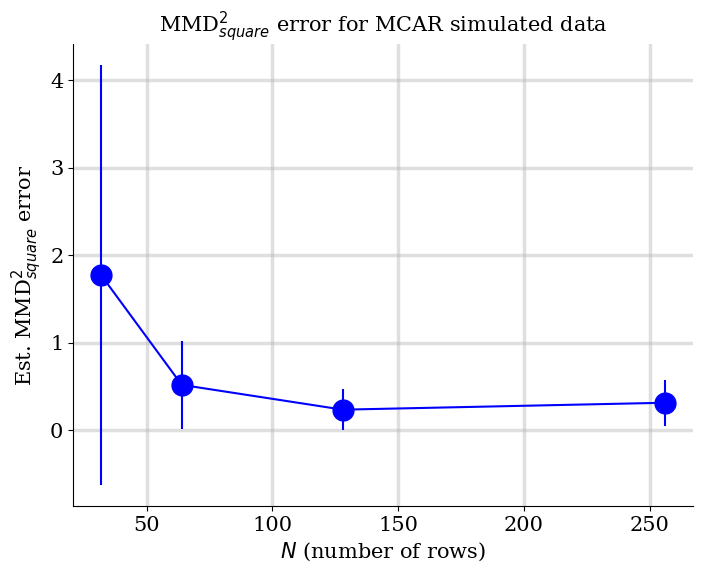

In [85]:
fig, ax = plt.subplots(figsize = (8, 6))
yerr = mcar_sims_std / np.sqrt((~np.isnan(mcar_sims_std)).sum())
xs = [2**5, 2**6,2**7, 2**8]
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)
ax.errorbar(xs, mcar_sims_means, marker = '.', alpha = 1., color = "blue", yerr=np.array([yerr, yerr]), linestyle = None, markersize = 30)
ax.set_title("MMD$_{square}^2$ error for MCAR simulated data")
ax.set_xlabel("$N$ (number of rows)")
ax.set_ylabel("Est. MMD$_{square}^2$ error")

Text(0, 0.5, 'Est. MMD$_{square}^2$ error')

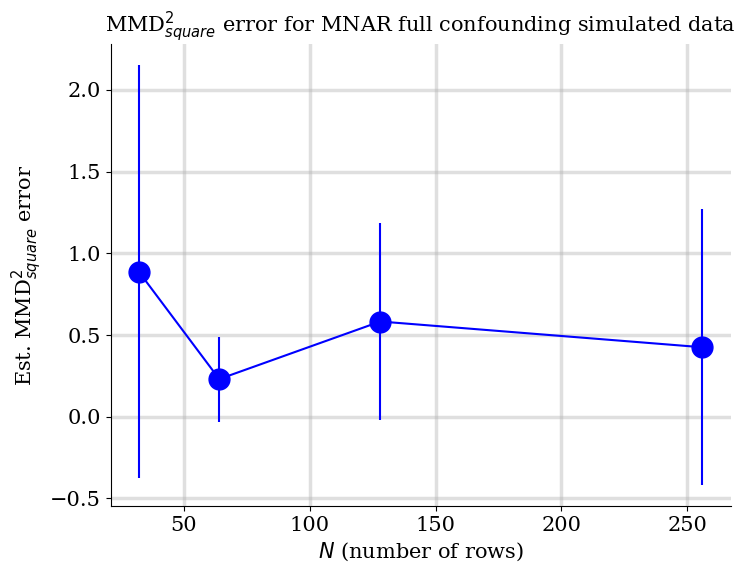

In [176]:
fig, ax = plt.subplots(figsize = (8, 6))
yerr = mnar_confounding_sims_std / np.sqrt((~np.isnan(mnar_confounding_sims_std)).sum())
xs = [2**5, 2**6,2**7, 2**8]
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, alpha=0.4)
ax.errorbar(xs, mnar_confounding_sims_means, marker = '.', alpha = 1., color = "blue", yerr=np.array([yerr, yerr]), linestyle = None, markersize = 30)
ax.set_title("MMD$_{square}^2$ error for MNAR full confounding simulated data")
ax.set_xlabel("$N$ (number of rows)")
ax.set_ylabel("Est. MMD$_{square}^2$ error")